# ДЗ 3

Марковский Артём Владиславович, 466636, J3310

Вариант: Программист, разработчик на Go

Репозиторий: https://github.com/shlaapnik/EngData/tree/mapreduce/MapReduce

In [1]:
import gc
import json
import math
import pathlib
import subprocess
import sys
import threading
import time
from collections import Counter, defaultdict
from importlib.metadata import version
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from boto3.s3.transfer import TransferConfig
from IPython import get_ipython
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

import duckdb_job
import mapreduce_job
import polars_job
from common import ACCESS_KEY, BUCKET, CSV_KEY, SECRET_KEY, s3_client

PROJECT = pathlib.Path.cwd()
DATA = PROJECT.parent / "big" / "vacancies_2024.csv"
DISKS = PROJECT.parent / "rustfs"
OUT = PROJECT / "out"
OUT.mkdir(exist_ok=True)

N_DISKS = 12
PART_SIZE = 16 * 1024 * 1024
MiB = 1024 * 1024
BLUE = "blue"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("python", sys.version.split()[0], "duckdb", version("duckdb"), "polars", version("polars"), "pandas", version("pandas"))
print("ядер", psutil.cpu_count(), "памяти, ГиБ", round(psutil.virtual_memory().total / 1024 ** 3, 1))

python 3.13.7 duckdb 2.0.0 polars 2.1.0 pandas 3.1.0
ядер 16 памяти, ГиБ 15.2


Замер ячейки: %%measure N название выполняет ячейку N раз и на каждом запуске считает время и память только этой ячейки. Перед каждым запуском перезапускаю RustFS и чищу мусор Python, чтобы все попытки стартовали одинаково, это время в замер не входит

In [2]:
measurements: list[dict[str, str | float]] = []


def used_memory() -> int:
    kernel = psutil.Process()
    total = kernel.memory_info().rss
    
    for child in kernel.children(recursive=True):
        try:
            total += child.memory_info().rss
        except psutil.Error:
            pass
            
    return total


def fresh_start() -> None:
    run_command("docker", "restart", "rustfs")
    
    for attempt in range(90):
        try:
            s3.get_object(Bucket=BUCKET, Key=CSV_KEY, Range="bytes=0-1048575")["Body"].read()
            break
        except Exception:
            time.sleep(2)
            
    time.sleep(5)
    gc.collect()


@register_cell_magic
def measure(line: str, cell: str) -> None:
    words = line.split()
    repeats = int(words[0])
    label = " ".join(words[1:])
    
    for attempt in range(1, repeats + 1):
        fresh_start()
        before = used_memory()
        peak = [before]
        running = [True]

        def watch() -> None:
            while running[0]:
                peak[0] = max(peak[0], used_memory())
                time.sleep(0.1)

        watcher = threading.Thread(target=watch)
        watcher.start()
        started = time.perf_counter()
        result = get_ipython().run_cell(cell)
        seconds = time.perf_counter() - started
        running[0] = False
        watcher.join()
        row: dict[str, str | float] = {"способ": label, "попытка": attempt, "время, с": round(seconds, 1),
                   "пик памяти, МиБ": round(peak[0] / MiB), "прирост памяти, МиБ": round((peak[0] - before) / MiB)}
        measurements.append(row)
        print(label, "попытка", attempt, "время", row["время, с"], "с, пик памяти", row["пик памяти, МиБ"],
                  "МиБ, прирост", row["прирост памяти, МиБ"], "МиБ")
                  
        if not result.success:
            raise RuntimeError("ячейка упала")

## 1. Хранилище

Поднимаю RustFS

In [3]:
def run_command(*arguments: str) -> str:
    result = subprocess.run(arguments, capture_output=True, text=True, encoding="utf-8", errors="replace")
    
    return (result.stdout + result.stderr).strip()

    
for disk in range(1, N_DISKS + 1):
    (DISKS / ("disk" + str(disk))).mkdir(parents=True, exist_ok=True)
    
status = run_command("docker", "ps", "-a", "--filter", "name=^rustfs$", "--format", "{{.Status}}")

if status == "":
    command = ["docker", "run", "-d", "--name", "rustfs", "-p", "9000:9000", "-p", "9001:9001",
               "-e", "RUSTFS_ACCESS_KEY=" + ACCESS_KEY, "-e", "RUSTFS_SECRET_KEY=" + SECRET_KEY,
               "-e", "RUSTFS_VOLUMES=/data/disk{1..." + str(N_DISKS) + "}",
               "-e", "RUSTFS_ADDRESS=:9000", "-e", "RUSTFS_CONSOLE_ADDRESS=:9001",
               "-e", "RUSTFS_CONSOLE_ENABLE=true", "-e", "RUSTFS_UNSAFE_BYPASS_DISK_CHECK=true"]
               
    for disk in range(1, N_DISKS + 1):
        name = "disk" + str(disk)
        command += ["--mount", "type=bind,source=" + str(DISKS / name) + ",target=/data/" + name]
        
    command.append("rustfs/rustfs:latest")
    print(run_command(*command))
elif not status.startswith("Up"):
    print(run_command("docker", "start", "rustfs"))

print(run_command("docker", "ps", "--filter", "name=^rustfs$"))

print(run_command("docker", "exec", "rustfs", "rustfs", "--version").splitlines()[0])
print(run_command("docker", "inspect", "rustfs", "--format", "{{range .Config.Env}}{{println .}}{{end}}"))

CONTAINER ID   IMAGE                  COMMAND                  CREATED        STATUS         PORTS                                                             NAMES
5fb9686150ff   rustfs/rustfs:latest   "/entrypoint.sh rust…"   22 hours ago   Up 7 minutes   0.0.0.0:9000-9001->9000-9001/tcp, [::]:9000-9001->9000-9001/tcp   rustfs
rustfs 1.0.1
RUSTFS_VOLUMES=/data/disk{1...12}
RUSTFS_ADDRESS=:9000
RUSTFS_CONSOLE_ADDRESS=:9001
RUSTFS_CONSOLE_ENABLE=true
RUSTFS_UNSAFE_BYPASS_DISK_CHECK=true
RUSTFS_ACCESS_KEY=rustfsadmin
RUSTFS_SECRET_KEY=rustfsadmin
PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
RUSTFS_CONSOLE_CORS_ALLOWED_ORIGINS=*
RUSTFS_OBS_LOGGER_LEVEL=warn
RUSTFS_OBS_LOG_DIRECTORY=/logs
RUSTFS_OBS_ENVIRONMENT=production


In [4]:
s3 = s3_client()

for attempt in range(60):
    try:
        s3.list_buckets()
        break
    except Exception:
        time.sleep(2)
        
if BUCKET not in [bucket["Name"] for bucket in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket=BUCKET)
print("бакеты:", [bucket["Name"] for bucket in s3.list_buckets()["Buckets"]])

бакеты: ['hh-lake']


Загружаю через S3 API, multipart upload частями по 16 МиБ в 8 потоков, время пишу в out/upload_log.json, при повторном запуске ячейка берёт его оттуда

In [5]:
size = DATA.stat().st_size
upload_log = OUT / "upload_log.json"
listed = s3.list_objects_v2(Bucket=BUCKET, Prefix=CSV_KEY)
uploaded = listed["Contents"][0]["Size"] if listed["KeyCount"] else 0

if uploaded == size and upload_log.exists():
    print("файл уже в бакете, лог загрузки:")
    print(upload_log.read_text(encoding="utf-8"))
else:
    lock = threading.Lock()
    bar = tqdm(total=size, unit="B", desc="upload")

    def progress(sent: int) -> None:
        with lock:
            bar.update(sent)

    started = time.perf_counter()
    transfer = TransferConfig(multipart_threshold=PART_SIZE, multipart_chunksize=PART_SIZE, max_concurrency=8)
    s3.upload_file(str(DATA), BUCKET, CSV_KEY, Callback=progress, Config=transfer)
    bar.close()
    seconds = time.perf_counter() - started
    log = {"key": "s3://" + BUCKET + "/" + CSV_KEY, "bytes": size, "seconds": round(seconds, 1),
           "MiB_per_s": round(size / MiB / seconds, 1), "parts": math.ceil(size / PART_SIZE)}
    upload_log.write_text(json.dumps(log, indent=1), encoding="utf-8")
    print(log)

файл уже в бакете, лог загрузки:
{
  "key": "s3://hh-lake/raw/vacancies_2024.csv",
  "bytes": 24970431974,
  "seconds": 744.0,
  "MiB_per_s": 32.0,
  "part_size": 16777216,
  "parts": 1489,
  "finished": "2026-10-26 16:23:36"
}


Проверка: лежит ли объект в бакете hh-lake и сколько места заняли папки-диски

In [6]:
head = s3.head_object(Bucket=BUCKET, Key=CSV_KEY)
print("s3://" + BUCKET + "/" + CSV_KEY, head["ContentLength"], "байт, локальный файл", size, "байт, совпадает:", head["ContentLength"] == size)

for item in s3.list_objects_v2(Bucket=BUCKET)["Contents"]:
    print(item["Key"], item["Size"])
    
disk_rows = []

for disk in range(1, N_DISKS + 1):
    files = [path for path in (DISKS / ("disk" + str(disk))).rglob("*") if path.is_file()]
    
    disk_rows.append({"диск": "disk" + str(disk), "файлов": len(files), "байт": sum(path.stat().st_size for path in files)})
    
disks = pd.DataFrame(disk_rows)
print(disks)
print("всего на дисках", disks["байт"].sum(), "байт, это", round(disks["байт"].sum() / size, 3), "от размера CSV")

s3://hh-lake/raw/vacancies_2024.csv 24970431974 байт, локальный файл 24970431974 байт, совпадает: True
parquet/skills.parquet 4852514
parquet/vacancies/data_0.parquet 233745515
raw/vacancies_2024.csv 24970431974
results/duckdb/skills_k1.csv 16467
results/duckdb/skills_k2.csv 307411
results/duckdb/skills_k3.csv 2510269
results/mapreduce/skills_k1.csv 16463
results/mapreduce/skills_k2.csv 307147
results/mapreduce/skills_k3.csv 2507949
results/polars/skills_k1.csv 16463
results/polars/skills_k2.csv 307147
results/polars/skills_k3.csv 2507949
variant/go_vacancies.parquet 142146
      диск  файлов        байт
0    disk1    3050  3153300016
1    disk2    3049  3153300016
2    disk3    3049  3153300016
3    disk4    3049  3153300016
4    disk5    3049  3153300016
5    disk6    3049  3153300016
6    disk7    3049  3153300016
7    disk8    3049  3153300016
8    disk9    3049  3153300016
9   disk10    3049  3153300016
10  disk11    3049  3153300016
11  disk12    3049  3153300016
всего на дисках 

## 2. ETL: CSV в Parquet

Каждый проход по CSV на 23 ГиБ занимает 2-4 минуты, поэтому для анализа кладу в бакет Parquet: только вакансии hh.ru, без описания,, зарплаты перевожу в числа. Навыки кладу двумя способами, исходной строкой и списком номнров со словарём номер -> навык, частым навыкам достаются маленькие номера, нормализация общая: нижний регистр, обрезка пробелов, удаление дублей

Строки сортирую по role, тогда у каждой row group узкий диапазон ролей, и движок по статистике min/max не читает группы, где нужной роли быть не может

In [7]:
for item in s3.list_objects_v2(Bucket=BUCKET, Prefix="parquet/").get("Contents", []):
    s3.delete_object(Bucket=BUCKET, Key=item["Key"])

In [8]:
%%measure 1 ETL CSV в Parquet
skills_total = duckdb_job.convert()

print("навыков в словаре", skills_total)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

навыков в словаре 184543
ETL CSV в Parquet попытка 1 время 347.9 с, пик памяти 5179 МиБ, прирост 4993 МиБ


In [9]:
parquet_objects = s3.list_objects_v2(Bucket=BUCKET, Prefix="parquet/")["Contents"]

for item in parquet_objects:
    print(item["Key"], item["Size"])
    
parquet_bytes = sum(item["Size"] for item in parquet_objects)
print("Parquet всего", parquet_bytes, "байт, CSV", size, "байт, меньше в", round(size / parquet_bytes), "раз")
tasks = mapreduce_job.plan_parquet("parquet")[0]

parquet/skills.parquet 4852514
parquet/vacancies/data_0.parquet 233745517
Parquet всего 238598031 байт, CSV 24970431974 байт, меньше в 105 раз
[master] row group всего 59 с нужной ролью по статистике min/max 1


## 3. Первичный анализ hh.ru

Дальше запросы DuckDB к Parquet в бакете

In [10]:
con = duckdb_job.connect()
con.execute("SET http_keep_alive = false")
con.execute("CREATE VIEW v AS SELECT * FROM " + duckdb_job.PARQUET)
con.sql("SELECT status, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df()

,status,vacancies
0,active,717043
1,not_active,6474031


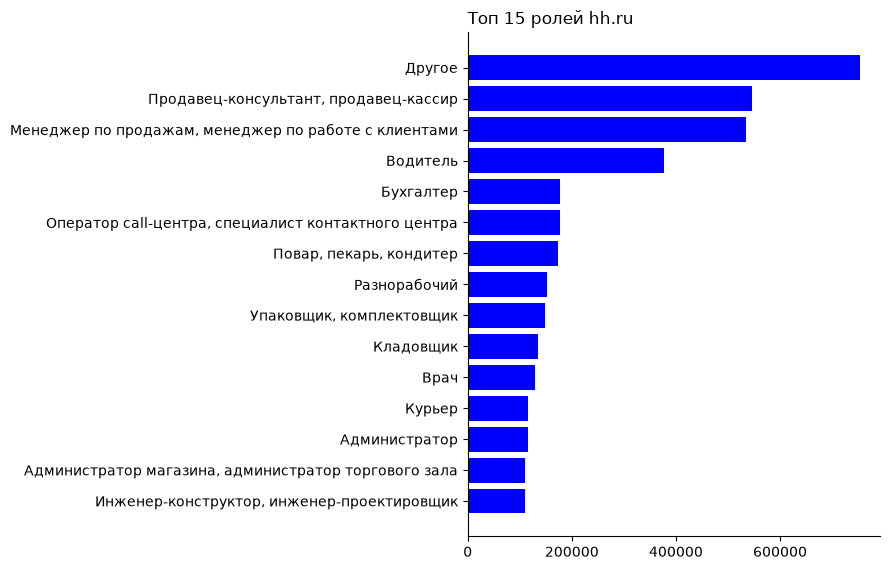

вакансий разработчиков 87803 разных ролей 174


In [11]:
def bar_chart(frame: pd.DataFrame, label_column: str, value_column: str, title: str, file_name: str) -> None:
    figure, axis = plt.subplots(figsize=(9, 0.32 * len(frame) + 1))
    
    axis.barh(frame[label_column][::-1], frame[value_column][::-1], color=BLUE)
    axis.set_title(title, loc="left")
    axis.grid(axis="x", color="white")
    axis.set_axisbelow(True)
    axis.ticklabel_format(axis="x", style="plain")
    axis.locator_params(axis="x", nbins=5)
    figure.tight_layout()
    figure.savefig(OUT / file_name, dpi=150)
    plt.show()


roles = con.sql("SELECT role, count(*) AS vacancies FROM v WHERE role IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 15").df()
bar_chart(roles, "role", "vacancies", "Топ 15 ролей hh.ru", "eda_roles.png")
developer_count, role_count = con.execute("""SELECT count(*) FILTER (WHERE role = 'Программист, разработчик'),
                                                 count(DISTINCT role) FROM v""").fetchall()[0]
print("вакансий разработчиков", developer_count, "разных ролей", role_count)

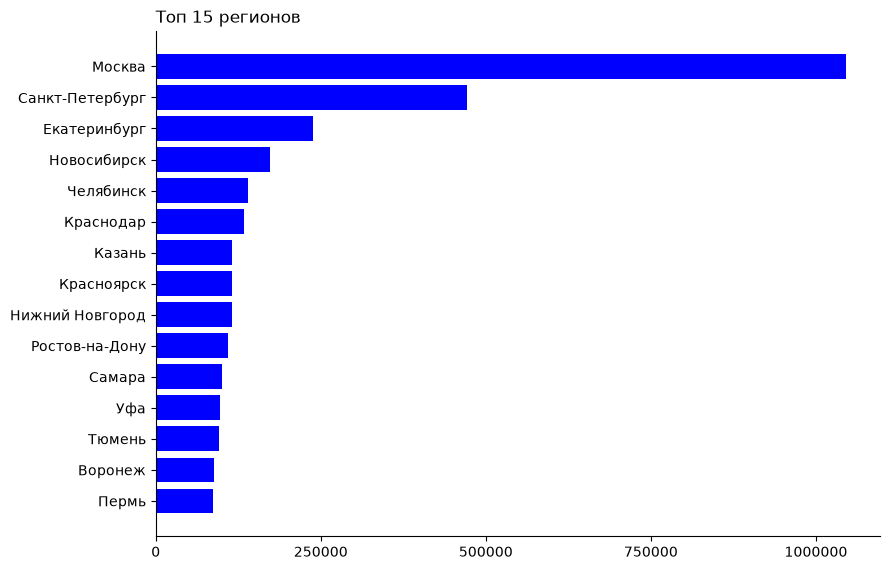

In [12]:
areas = con.sql("SELECT area, count(*) AS vacancies FROM v WHERE area IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 15").df()
bar_chart(areas, "area", "vacancies", "Топ 15 регионов", "eda_areas.png")

In [13]:
print(con.sql("SELECT experience, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df())

print(con.sql("SELECT schedule, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df())

           experience  vacancies
0         Более 6 лет     108787
1           Нет опыта    2947161
2  От 1 года до 3 лет    3097397
3       От 3 до 6 лет     965922
4                 NaN      71807
           schedule  vacancies
0    Вахтовый метод     600547
1     Гибкий график     433402
2       Полный день    4619811
3    Сменный график     992814
4  Удаленная работа     472693
5               NaN      71807


вакансий hh 7191074
с навыками 47.6 % вакансий
в среднем навыков у вакансии, где они есть 6.06


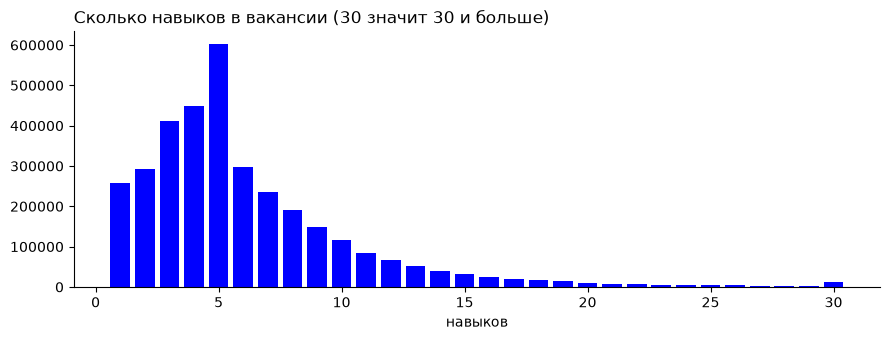

In [14]:
vacancy_count, with_skills_pct, skills_mean = con.execute("""SELECT count(*), round(100 * avg((len(skill_ids) > 0)::INT), 1),
                                                                    round(avg(len(skill_ids)) FILTER (WHERE len(skill_ids) > 0), 2)
                                                             FROM v""").fetchall()[0]
print("вакансий hh", vacancy_count)
print("с навыками", with_skills_pct, "% вакансий")
print("в среднем навыков у вакансии, где они есть", skills_mean)
skill_counts = con.sql("SELECT least(len(skill_ids), 30) AS n, count(*) AS vacancies FROM v WHERE len(skill_ids) > 0 GROUP BY 1 ORDER BY 1").df()
figure, axis = plt.subplots(figsize=(9, 3.5))
axis.bar(skill_counts["n"], skill_counts["vacancies"], color=BLUE)
axis.set_title("Сколько навыков в вакансии (30 значит 30 и больше)", loc="left")

axis.set_xlabel("навыков")
figure.tight_layout()
figure.savefig(OUT / "eda_skills_count.png", dpi=150)
plt.show()

In [15]:
months = con.sql("SELECT strftime(published_at, '%Y-%m') AS month, count(*) AS vacancies FROM v GROUP BY 1 ORDER BY 1").df()
print(months)

      month  vacancies
0   2023-11         28
1   2023-12     441082
2   2024-01     465049
3   2024-02     752457
4   2024-03     847536
5   2024-04     271293
6   2024-05     648338
7   2024-06     601343
8   2024-07     879847
9   2024-08    1253355
10  2024-09     958939
11      NaN      71807


## 4. Зарплатная вилка

In [16]:
fork = con.sql("""
    SELECT CASE WHEN salary_from IS NULL AND salary_to IS NULL THEN '1 нет зарплаты'
                WHEN salary_to IS NULL THEN '2 только от'
                WHEN salary_from IS NULL THEN '3 только до'
                ELSE '4 от и до' END AS fork,
           count(*) AS vacancies
    FROM v GROUP BY ALL ORDER BY ALL""").df()
    
fork["%"] = (100 * fork["vacancies"] / fork["vacancies"].sum()).round(1)
fork

,fork,vacancies,%
0,1 нет зарплаты,1130419,15.7
1,2 только от,2701712,37.6
2,3 только до,352253,4.9
3,4 от и до,3006690,41.8


In [17]:
print(con.sql("""SELECT currency, count(*) AS vacancies FROM v
                 WHERE salary_from IS NOT NULL OR salary_to IS NOT NULL GROUP BY ALL ORDER BY 2 DESC""").df())
print(con.sql("""SELECT gross, count(*) AS vacancies FROM v
                 WHERE currency = 'RUR' GROUP BY ALL ORDER BY ALL""").df())

  currency  vacancies
0      RUR    6043062
1      USD       6160
2      KZT       5204
3      BYR       4464
4      EUR       1009
5      UZS        622
6      KGS        114
7      AZN         10
8      GEL          7
9      UAH          3
   gross  vacancies
0  false    3886776
1   true    2152385
2    NaN       3901


## 5. Рынок IT

IT это раздел hh "Информационные технологии"

Границы беру от 10000, у IT ролей границы меньше 10000 в 0.2% рублёвых вакансий. Недостающую границу восстанавливаю через k, это медиана отношения "до/от" по вакансиям роли с обеими границами, у каждой роли своё k, дальше беру середину и перевожу net в gross. Вакансии hh вышли с 2023-11-13 по 2024-09-15, значит шкала НДФЛ одна: 13% с дохода до 5 млн в год и 15% сверху, в месяц это net до 362500

In [18]:
IT_ROLES = ["BI-аналитик, аналитик данных", "DevOps-инженер", "Аналитик", "Арт-директор, креативный директор",
            "Бизнес-аналитик", "Гейм-дизайнер", "Дата-сайентист", "Дизайнер, художник",
            "Директор по информационным технологиям (CIO)", "Менеджер продукта", "Методолог", "Программист, разработчик",
            "Продуктовый аналитик", "Руководитель группы разработки", "Руководитель отдела аналитики",
            "Руководитель проектов", "Сетевой инженер", "Системный администратор", "Системный аналитик",
            "Системный инженер", "Специалист по информационной безопасности", "Специалист технической поддержки",
            "Тестировщик", "Технический директор (CTO)", "Технический писатель"]

con.execute("""
CREATE OR REPLACE TEMP TABLE market AS
WITH hh AS (
    SELECT role, area, experience, schedule, gross,
           CASE WHEN role = 'Программист, разработчик' THEN lower(name) END AS name,
           CASE WHEN currency = 'RUR' AND salary_from >= 10000 THEN salary_from END AS salary_from,
           CASE WHEN currency = 'RUR' AND salary_to >= 10000 THEN salary_to END AS salary_to
    FROM v
), ratio AS (
    SELECT role, median(salary_to / salary_from) AS k FROM hh
    WHERE salary_from IS NOT NULL AND salary_to IS NOT NULL GROUP BY role
), point AS (
    SELECT hh.*, ratio.k,
           (coalesce(salary_from, salary_to / ratio.k) + coalesce(salary_to, salary_from * ratio.k)) / 2 AS point
    FROM hh LEFT JOIN ratio USING (role)
)
SELECT *, coalesce(role IN (SELECT unnest($roles)), false) AS it,
       CASE WHEN gross = 'false' AND point <= 362500 THEN point / 0.87
            WHEN gross = 'false' THEN (5000000 + (12 * point - 4350000) / 0.85) / 12
            ELSE point END AS salary
FROM point
""", {"roles": IT_ROLES})

con.sql("""SELECT CASE WHEN it THEN 'IT' ELSE 'остальной hh' END AS segment, count(*) AS vacancies,
                  round(100 * count(*) / sum(count(*)) OVER (), 1) AS share_pct,
                  round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                  round(median(salary)) AS median_gross,
                  round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) AS median_1_3_gross,
                  round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) AS median_3_gross,
                  round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                  round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                  round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct,
                  round(100 * avg((experience = 'Нет опыта')::INT), 1) AS no_experience_pct,
                  round(100 * avg((area IN ('Москва', 'Санкт-Петербург'))::INT), 1) AS moscow_spb_pct
           FROM market GROUP BY 1 ORDER BY 1""").df()

,segment,vacancies,share_pct,with_salary_pct,median_gross,median_1_3_gross,median_3_gross,remote_pct,experience_1_3_pct,experience_3_pct,no_experience_pct,moscow_spb_pct
0,IT,352871,4.9,48.9,95000.0,94828.0,189655.0,23.1,47.7,37.4,14.9,48.3
1,остальной hh,6838203,95.1,85.6,78818.0,86207.0,124138.0,5.8,43.3,13.9,42.8,19.9


Роли внутри IT по числу вакансий

                                            role  vacancies  it_share_pct     k  with_salary_pct       p25  median_gross       p75  median_1_3_gross  median_3_gross  remote_pct  experience_1_3_pct  \
0                       Программист, разработчик      87803          24.9  1.43             45.1   97701.0      164943.0  241379.0          139573.0        229885.0        28.2                42.5   
1               Специалист технической поддержки      49145          13.9  1.29             72.3   45977.0       54598.0   72250.0           65681.0        114286.0        41.8                46.0   
2                                       Аналитик      30112           8.5  1.31             39.0   66313.0       95376.0  155172.0           97701.0        198939.0        21.3                56.9   
3                        Системный администратор      29723           8.4  1.20             65.2   57471.0       75862.0  105364.0           75862.0        110000.0         4.9                59.7   


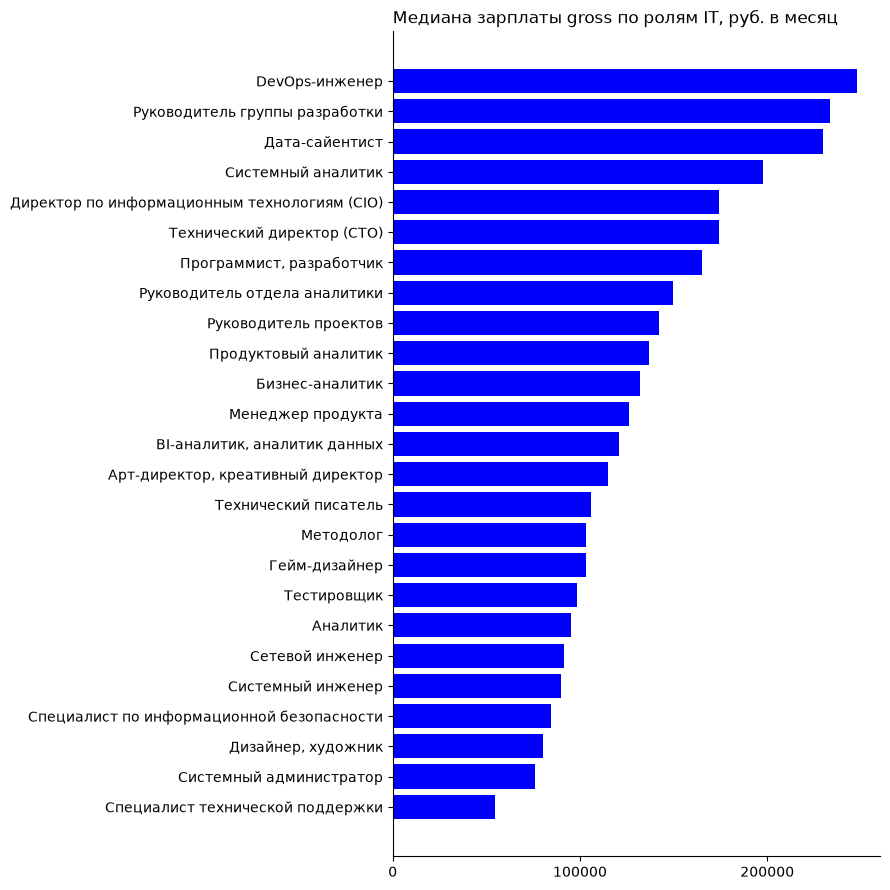

In [19]:
it_roles = con.sql("""SELECT role, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS it_share_pct,
                             round(any_value(k), 2) AS k, round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                             round(quantile_cont(salary, 0.25)) AS p25, round(median(salary)) AS median_gross,
                             round(quantile_cont(salary, 0.75)) AS p75,
                             round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) AS median_1_3_gross,
                             round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) AS median_3_gross,
                             round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                             round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                             round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct
                      FROM market WHERE it GROUP BY role ORDER BY vacancies DESC""").df()
print(it_roles)
print("ранговая корреляция медианы и доли вакансий с зарплатой по ролям",
      round(it_roles["median_gross"].rank().corr(it_roles["with_salary_pct"].rank()), 2))
bar_chart(it_roles.sort_values("median_gross", ascending=False), "role", "median_gross",
          "Медиана зарплаты gross по ролям IT, руб. в месяц", "it_roles_salary.png")

Языки у разработчиков: язык ищу в названии вакансий роли "Программист, разработчик", одна вакансия может попасть в несколько языков. Go тут ищу по названию, поэтому вакансий меньше, чем в варианте, где я беру ещё вакансии с Go в навыках

In [20]:
WORD = "(^|[^a-zа-яё0-9_])"
END = "([^a-zа-яё0-9_]|$)"
LANGUAGES = {
    "Python": WORD + "(python|питон)" + END,
    "Java": WORD + "java" + END,
    "JavaScript, TypeScript, frontend": WORD + "(javascript|typescript|js|ts|node|nodejs|react|vue|angular|frontend|фронтенд)" + END,
    "PHP": WORD + "php" + END,
    "1С": WORD + "(1с|1c)" + END,
    "C#, .NET": "c#|с#|\\.net",
    "C++": "c\\+\\+|с\\+\\+",
    "Go": duckdb_job.NAME_GO.strip("'"),
    "Kotlin, Android": WORD + "(kotlin|android)" + END,
    "Swift, iOS": WORD + "(swift|ios)" + END,
    "Ruby": WORD + "ruby" + END,
    "Rust": WORD + "rust" + END,
    "Scala": WORD + "scala" + END,
}
developers_total = con.execute("SELECT count(*) FROM market WHERE role = 'Программист, разработчик'").fetchall()[0][0]
language_rows = []

for language, pattern in LANGUAGES.items():
    language_rows.append(con.execute("""SELECT ? AS language, count(*) AS vacancies,
                                               round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                                               round(median(salary)) AS median_gross,
                                               CASE WHEN count(salary) FILTER (WHERE experience = 'От 1 года до 3 лет') >= 10
                                                    THEN round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) END AS median_1_3_gross,
                                               CASE WHEN count(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет')) >= 10
                                                    THEN round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) END AS median_3_gross,
                                               round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                                               round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                                               round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct
                                        FROM market WHERE role = 'Программист, разработчик' AND regexp_matches(name, ?)""",
                                     [language, pattern]).df())

languages = pd.concat(language_rows).sort_values("vacancies", ascending=False).reset_index(drop=True)
languages.insert(2, "developers_pct", (100 * languages["vacancies"] / developers_total).round(1))
print("вакансий разработчиков", developers_total)
languages

вакансий разработчиков 87803


,language,vacancies,developers_pct,with_salary_pct,median_gross,median_1_3_gross,median_3_gross,remote_pct,experience_1_3_pct,experience_3_pct
0,1С,21244,24.2,60.3,182143.0,167488.0,230296.0,27.1,47.9,42.7
1,"JavaScript, TypeScript, frontend",9219,10.5,40.8,170000.0,130000.0,235000.0,36.3,39.2,55.9
2,Java,6100,6.9,20.8,219300.0,166092.0,281609.0,35.0,25.5,68.1
3,PHP,5379,6.1,56.9,167488.0,139573.0,218391.0,42.1,45.2,49.0
4,"C#, .NET",4355,5.0,33.1,201149.0,139573.0,255000.0,37.8,33.0,62.1
5,Python,3897,4.4,34.2,189655.0,154265.0,250000.0,31.5,37.2,58.1
6,C++,3462,3.9,34.5,201149.0,149425.0,241379.0,19.2,31.1,63.9
7,Go,2565,2.9,23.9,293103.0,212644.0,344828.0,35.8,26.5,71.2
8,"Kotlin, Android",2036,2.3,29.1,229885.0,167488.0,301724.0,35.7,31.6,64.2
9,"Swift, iOS",1127,1.3,28.6,208128.0,150776.0,293103.0,36.1,30.8,62.6


IT по регионам: топ 10 регионов по числу вакансий IT, доля IT среди всех вакансий региона и медианы

In [21]:
it_regions = con.sql("""SELECT area, count(*) FILTER (WHERE it) AS it_vacancies,
                  round(100 * count(*) FILTER (WHERE it) / sum(count(*) FILTER (WHERE it)) OVER (), 1) AS of_all_it_pct,
                  round(100 * count(*) FILTER (WHERE it) / count(*), 1) AS it_in_region_pct,
                  round(median(salary) FILTER (WHERE it)) AS it_median_gross,
                  round(median(salary) FILTER (WHERE NOT it)) AS other_median_gross,
                  round(100 * avg((schedule = 'Удаленная работа')::INT) FILTER (WHERE it), 1) AS it_remote_pct
           FROM market GROUP BY area ORDER BY it_vacancies DESC LIMIT 10""").df()
con.execute("DROP TABLE market")
it_regions

,area,it_vacancies,of_all_it_pct,it_in_region_pct,it_median_gross,other_median_gross,it_remote_pct
0,Москва,133338,37.8,12.8,160920.0,105776.0,24.0
1,Санкт-Петербург,37059,10.5,7.9,121000.0,89080.0,21.4
2,Екатеринбург,13731,3.9,5.8,96177.0,80179.0,20.6
3,Новосибирск,10184,2.9,5.9,97701.0,79759.0,20.8
4,Казань,8055,2.3,6.9,91954.0,75758.0,28.4
5,Нижний Новгород,7271,2.1,6.3,85000.0,71924.0,26.0
6,Краснодар,6477,1.8,4.8,83744.0,79639.0,25.8
7,Самара,5307,1.5,5.3,75862.0,71167.0,26.1
8,Ростов-на-Дону,5089,1.4,4.7,80000.0,74713.0,25.5
9,Воронеж,4773,1.4,5.4,75000.0,68966.0,24.6


Эх верните мой 2024...

IT это 4.9% вакансий hh, и больше там платят опытным: с опытом 1-3 года медиана выше остального рынка на 10%, от 3 лет на 53%. Go восьмой язык по числу вакансий и самый дорогой из крупных при одинаковом опыте, с опытом 1-3 года 212644 против 167488 у следующих за ним

## 6. Вакансии Go

Либо в названии есть Go в любом написании: go, golang, goland, go-lang, голанг, голэнг, в том числе с русской о или а внутри, как в "Gо Developer", русское "го" считаю только рядом со словами "разработчик" или "программист", иначе в выборку попадают "ГО и ЧС" и "1-го", либо Go стоит в навыках, а в названии нет другого языка или frontend (Python, PHP, Java, C#, C++, Node, JS и т.д.)

Навыки режу по ";", перевожу в нижний регистр и обрезаю пробелы, golang, go lang, программирование на go и похожее свожу к go, дубли внутри вакансии убираю

In [22]:
con.execute(duckdb_job.fill("""
CREATE OR REPLACE TEMP TABLE developers AS
SELECT *, regexp_matches(lower(name), NAME_GO) AS name_go,
       list_contains(skills, 'go') AS skill_go,
       regexp_matches(lower(name), OTHER_LANGUAGE) AS other_language
FROM (
    SELECT *, list_distinct(list_filter(
               list_transform(string_split(lower(key_skills), ';'), lambda x:
                   CASE WHEN regexp_matches(trim(x, ' '), SKILL_GO) THEN 'go' ELSE trim(x, ' ') END),
               lambda x: x <> '')) AS skills
    FROM v WHERE role = 'Программист, разработчик')
"""))
con.sql("""SELECT name_go AS go_в_названии, skill_go AS go_в_навыках, other_language AS другой_язык_в_названии,
                  count(*) AS vacancies, name_go OR (skill_go AND NOT other_language) AS берём
           FROM developers WHERE name_go OR skill_go GROUP BY ALL ORDER BY ALL""").df()

,go_в_названии,go_в_навыках,другой_язык_в_названии,vacancies,берём
0,False,True,False,340,True
1,False,True,True,231,False
2,True,False,False,685,True
3,True,False,True,86,True
4,True,True,False,1604,True
5,True,True,True,190,True


Какие названия попадают только по навыку и какие из них отсеиваются

In [23]:
print(con.sql("""SELECT name, count(*) AS vacancies FROM developers
                 WHERE skill_go AND NOT name_go AND NOT other_language GROUP BY 1 ORDER BY 2 DESC LIMIT 10""").df())
                 
print(con.sql("""SELECT name, count(*) AS vacancies FROM developers
                 WHERE skill_go AND NOT name_go AND other_language GROUP BY 1 ORDER BY 2 DESC LIMIT 10""").df())

                                                name  vacancies
0                                Backend-разработчик         27
1                         Стажер-разработчик бэкенда         19
2  Backend-разработчик (Middle) в команду сбора и...          8
3                                Backend разработчик          8
4                     Разработчик серверной части ПО          6
5  Backend-разработчик (Middle) в команду открыты...          5
6                                Ведущий разработчик          5
7                                   VOIP разработчик          5
8           Старший бэкенд-разработчик в Образование          5
9  Senior backend разработчик / Ведущий backend и...          5
                                                name  vacancies
0                               С# Backend Developer          7
1                                Node.js разработчик          6
2                                 Разработчик NodeJS          6
3                                    PHP

Срез Go сохраняю в бакет, s3://hh-lake/variant/go_vacancies.parquet

In [24]:
con.execute("""CREATE OR REPLACE TEMP TABLE go AS
               SELECT vacancy_id, source, published_at, area, employer_id, name, salary_from, salary_to, currency, gross,
                      experience, schedule, employment, list_sort(skills) AS skills
               FROM developers WHERE name_go OR (skill_go AND NOT other_language)""")
con.execute("COPY go TO 's3://hh-lake/variant/go_vacancies.parquet' (FORMAT parquet)")
variant = con.sql("SELECT * FROM go ORDER BY vacancy_id").df()
variant["skills"] = variant["skills"].map(list)
print("вакансий Go", len(variant), "источники", variant["source"].value_counts().to_dict())

вакансий Go 2905 источники {'hh': 2905}


In [25]:
print(con.sql("""SELECT CASE WHEN salary_from IS NULL AND salary_to IS NULL THEN '1 нет зарплаты'
                             WHEN salary_to IS NULL THEN '2 только от'
                             WHEN salary_from IS NULL THEN '3 только до'
                             ELSE '4 от и до' END AS fork, currency, count(*) AS vacancies
                 FROM go GROUP BY ALL ORDER BY ALL""").df())
print(con.sql("SELECT experience, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct FROM go GROUP BY 1 ORDER BY 2 DESC").df())
print(con.sql("SELECT schedule, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct FROM go GROUP BY 1 ORDER BY 2 DESC").df())

             fork currency  vacancies
0  1 нет зарплаты      NaN       2124
1     2 только от      RUR        235
2     2 только от      USD          7
3     3 только до      EUR          2
4     3 только до      RUR        196
5     3 только до      USD         14
6       4 от и до      KZT          3
7       4 от и до      RUR        298
8       4 от и до      USD         26
           experience  vacancies   pct
0       От 3 до 6 лет       1817  62.5
1  От 1 года до 3 лет        794  27.3
2         Более 6 лет        201   6.9
3           Нет опыта         93   3.2
           schedule  vacancies   pct
0       Полный день       1772  61.0
1  Удаленная работа        989  34.0
2     Гибкий график        142   4.9
3    Сменный график          2   0.1


               area  vacancies  with_rub_salary  with_skills
0            Москва       1750              390         1321
1   Санкт-Петербург        411              100          329
2      Екатеринбург         93               24           67
3   Нижний Новгород         76               11           57
4       Новосибирск         72               19           60
5            Казань         67               21           55
6         Краснодар         33               13           29
7    Ростов-на-Дону         32               15           22
8            Самара         27                7           22
9            Рязань         16                5            9
10           Алматы         14                0           11
11          Воронеж         14                7           12
12        Ульяновск         14                8           13
13      Калининград         12                4            9
14            Пенза         12                2           11


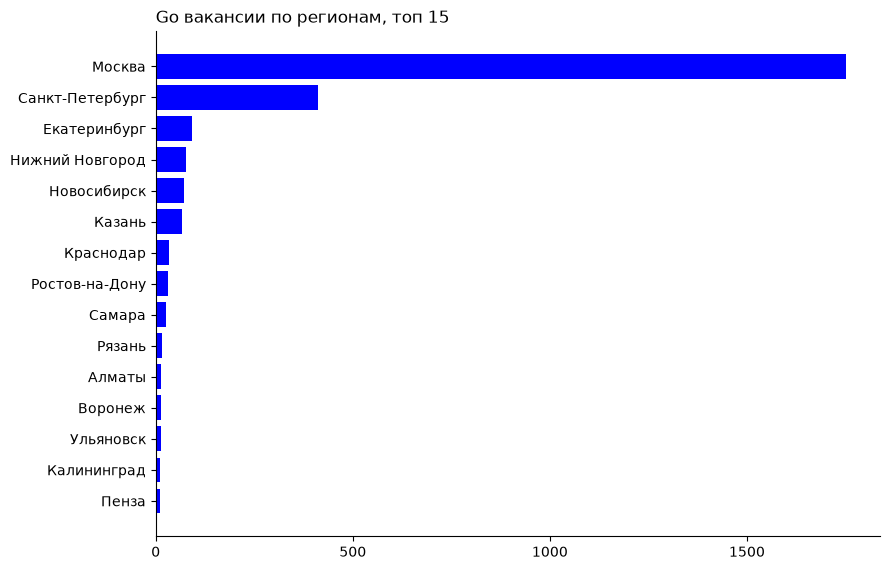

In [26]:
go_areas = con.sql("""SELECT area, count(*) AS vacancies,
                             count(*) FILTER (WHERE currency = 'RUR') AS with_rub_salary,
                             count(*) FILTER (WHERE len(skills) > 0) AS with_skills
                      FROM go GROUP BY 1 ORDER BY 2 DESC LIMIT 15""").df()
                      
print(go_areas)
bar_chart(go_areas, "area", "vacancies", "Go вакансии по регионам, топ 15", "go_areas.png")

In [27]:
go_total, go_employers, go_skills_mean, go_without_skills = con.execute("""SELECT count(*), count(DISTINCT employer_id),
                                round(avg(len(skills)) FILTER (WHERE len(skills) > 0), 2),
                                count(*) FILTER (WHERE len(skills) = 0)
                         FROM go""").fetchall()[0]
print("вакансий", go_total, "работодателей", go_employers, "навыков в среднем у вакансий с навыками", go_skills_mean,
      "без навыков", go_without_skills)
top_employers = con.sql("SELECT employer_id, count(*) AS vacancies FROM go GROUP BY 1 ORDER BY 2 DESC LIMIT 5").df()
print(top_employers)
print("доля топ 5 работодателей", round(100 * top_employers["vacancies"].sum() / len(variant), 1), "%")

вакансий 2905 работодателей 765 навыков в среднем у вакансий с навыками 5.96 без навыков 665
  employer_id  vacancies
0        2180        217
1       87021         88
2        3529         84
3        1740         74
4       78638         56
доля топ 5 работодателей 17.9 %


## 7. Навыки, пары и тройки на CSV

Все три способа читают исходный CSV из бакета, s3://hh-lake/raw/vacancies_2024.csv

Свой MapReduce: мастер режет файл на сплиты по 64 МиБ, маппер читает сплит кусками по 8 МиБ, берёт строки, которые начинаются внутри сплита, первую неполную пропускает, последнюю дочитывает за концом. Map не разбирает csv у строк, где в байтах нет "Программист, разработчик", остальные проверяет по условию и выдаёт все сочетания по 1, 2 и 3 навыка. Combiner суммирует их в маппере и раскладывает на 4 партиции по crc32 от ключа, reduce складывает свою партицию из выходов всех map-тасков. Упавший map-таск мастер перезапускает до 3 раз, а если умер сам процесс-воркер, пересоздаёт пул и заново запускает таски, которые были в работе

DuckDB читает тот же объект через httpfs, условие и нормализацию я написал на SQL, число всех строк и строки нужной роли DuckDB собирет в одном агрегате. Пары и тройки это self join таблицы (вакансия, навык) с условием a.skill < b.skill < c.skill, так каждое сочетание попадает в счёт один раз

Polars читает CSV через scan_csv потоковым движком и фильтрует роль при чтении, дальше как в DuckDB

Каждый способ запускаю 3 раза с замером, все три пишут результаты в бакет в results/ в замеряемой ячейке

In [28]:
%%measure 3 MapReduce CSV
mr_summary, mr_rows = mapreduce_job.run("csv", out_prefix="results/mapreduce")

mapreduce csv, map тасков:   0%|          | 0/373 [00:00<?, ?it/s]

MapReduce CSV попытка 1 время 150.9 с, пик памяти 1882 МиБ, прирост 1382 МиБ


mapreduce csv, map тасков:   0%|          | 0/373 [00:00<?, ?it/s]

MapReduce CSV попытка 2 время 148.4 с, пик памяти 1753 МиБ, прирост 1377 МиБ


mapreduce csv, map тасков:   0%|          | 0/373 [00:00<?, ?it/s]

MapReduce CSV попытка 3 время 152.3 с, пик памяти 1679 МиБ, прирост 1468 МиБ


In [29]:
%%measure 3 DuckDB CSV
duck_summary, duck_rows = duckdb_job.run("csv", out_prefix="results/duckdb")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB CSV попытка 1 время 230.7 с, пик памяти 2968 МиБ, прирост 2754 МиБ


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB CSV попытка 2 время 265.9 с, пик памяти 2954 МиБ, прирост 2694 МиБ


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB CSV попытка 3 время 274.0 с, пик памяти 3021 МиБ, прирост 2733 МиБ


In [30]:
%%measure 3 Polars CSV
polars_summary, polars_rows = polars_job.run("csv", out_prefix="results/polars")

polars csv, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars CSV попытка 1 время 141.5 с, пик памяти 2086 МиБ, прирост 1809 МиБ


polars csv, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars CSV попытка 2 время 127.4 с, пик памяти 2032 МиБ, прирост 1437 МиБ


polars csv, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars CSV попытка 3 время 128.6 с, пик памяти 2060 МиБ, прирост 1551 МиБ


Отказ маппера: процесс-воркер с таском 120 умирает через os._exit, мастер пересоздаёт пул и заново запускает таски, которые были в работе (12 выполнялись и 2 ждали в очереди пула), остальные результаты у мастера уже есть

In [31]:
fresh_start()
crash_summary, _ = mapreduce_job.run("csv", fail=120)
print("перезапуски (таск: попыток):", crash_summary["retried"])
print("результат совпал с обычным прогоном:", crash_summary["sha256"] == mr_summary["sha256"], "время", crash_summary["total_s"], "с")

mapreduce csv, map тасков:   0%|          | 0/373 [00:00<?, ?it/s]

[master] умер процесс-воркер, пул пересоздан, перезапуск тасков которые были в работе: [113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126]
перезапуски (таск: попыток): {113: 2, 114: 2, 115: 2, 116: 2, 117: 2, 118: 2, 119: 2, 120: 2, 121: 2, 122: 2, 123: 2, 124: 2, 125: 2, 126: 2}
результат совпал с обычным прогоном: True время 154.0 с


Сверка трёх способов по каждому ключу и его частоте, потом контрольные числа

In [32]:
for size in (1, 2, 3):
    reference = dict(mr_rows[size])
    
    for label, rows in [("DuckDB", duck_rows), ("Polars", polars_rows)]:
        other = dict(rows[size])
        only_mr = len(set(reference) - set(other))
        only_other = len(set(other) - set(reference))
        different = sum(1 for key in reference if key in other and reference[key] != other[key])
        print("k =", size, "MapReduce и", label, ": ключей", len(reference), "и", len(other), "| только в MapReduce", only_mr,
              "| только в", label, only_other, "| разные частоты", different)

k = 1 MapReduce и DuckDB : ключей 853 и 853 | только в MapReduce 0 | только в DuckDB 0 | разные частоты 0
k = 1 MapReduce и Polars : ключей 853 и 853 | только в MapReduce 0 | только в Polars 0 | разные частоты 0
k = 2 MapReduce и DuckDB : ключей 10999 и 10999 | только в MapReduce 0 | только в DuckDB 0 | разные частоты 0
k = 2 MapReduce и Polars : ключей 10999 и 10999 | только в MapReduce 0 | только в Polars 0 | разные частоты 0
k = 3 MapReduce и DuckDB : ключей 67009 и 67009 | только в MapReduce 0 | только в DuckDB 0 | разные частоты 0
k = 3 MapReduce и Polars : ключей 67009 и 67009 | только в MapReduce 0 | только в Polars 0 | разные частоты 0


In [33]:
control = pd.DataFrame({
    "MapReduce": [mr_summary["rows"], mr_summary["variant_vacancies"], mr_summary["with_skills"]]
                 + [mr_summary["unique"][size] for size in (1, 2, 3)]
                 + [mr_summary["total_count"][size] for size in (1, 2, 3)]
                 + [mr_summary["sha256"][size][:16] for size in (1, 2, 3)],
    "DuckDB": [duck_summary["rows"], duck_summary["variant_vacancies"], duck_summary["with_skills"]]
              + [duck_summary["unique"][size] for size in (1, 2, 3)]
              + [duck_summary["total_count"][size] for size in (1, 2, 3)]
              + [duck_summary["sha256"][size][:16] for size in (1, 2, 3)],
    "Polars": ["-", polars_summary["variant_vacancies"], polars_summary["with_skills"]]
              + [polars_summary["unique"][size] for size in (1, 2, 3)]
              + [polars_summary["total_count"][size] for size in (1, 2, 3)]
              + [polars_summary["sha256"][size][:16] for size in (1, 2, 3)],
}, index=["строк в файле", "вакансий Go", "из них с навыками", "уникальных навыков", "уникальных пар", "уникальных троек",
          "сумма частот навыков", "сумма частот пар", "сумма частот троек", "SHA-256 навыков", "SHA-256 пар", "SHA-256 троек"])
          
control

,MapReduce,DuckDB,Polars
строк в файле,10205102,10205102,-
вакансий Go,2905,2905,2905
из них с навыками,2240,2240,2240
уникальных навыков,853,853,853
уникальных пар,10999,10999,10999
уникальных троек,67009,67009,67009
сумма частот навыков,13355,13355,13355
сумма частот пар,48945,48945,48945
сумма частот троек,155008,155008,155008
SHA-256 навыков,4796a1882da3f830,4796a1882da3f830,4796a1882da3f830


In [34]:
for item in s3.list_objects_v2(Bucket=BUCKET, Prefix="results/")["Contents"]:
    print(item["Key"], item["Size"])

results/duckdb/skills_k1.csv 16467
results/duckdb/skills_k2.csv 307411
results/duckdb/skills_k3.csv 2510269
results/mapreduce/skills_k1.csv 16463
results/mapreduce/skills_k2.csv 307147
results/mapreduce/skills_k3.csv 2507949
results/polars/skills_k1.csv 16463
results/polars/skills_k2.csv 307147
results/polars/skills_k3.csv 2507949


Топ-10 навыков, пар и троек без go, он есть в каждой вакансии, доля от всех вакансий Go

In [35]:
top_tables = {}

for size in (1, 2, 3):
    without_go = [(combo, count) for combo, count in mr_rows[size] if "go" not in combo][:10]
    top_tables[size] = pd.DataFrame({"сочетание": [" + ".join(combo) for combo, _ in without_go],
                                     "вакансий": [count for _, count in without_go]})
                                     
    top_tables[size]["доля, %"] = (100 * top_tables[size]["вакансий"] / mr_summary["variant_vacancies"]).round(1)
    print(top_tables[size])
    print()

    сочетание  вакансий  доля, %
0  postgresql      1010     34.8
1      docker       622     21.4
2         sql       482     16.6
3         git       480     16.5
4       linux       449     15.5
5       kafka       414     14.3
6  kubernetes       397     13.7
7       redis       345     11.9
8    rabbitmq       335     11.5
9      python       323     11.1

                 сочетание  вакансий  доля, %
0      docker + postgresql       398     13.7
1       kafka + postgresql       287      9.9
2         git + postgresql       274      9.4
3         postgresql + sql       241      8.3
4  kubernetes + postgresql       234      8.1
5             docker + git       232      8.0
6       postgresql + redis       221      7.6
7    postgresql + rabbitmq       220      7.6
8      docker + kubernetes       214      7.4
9                git + sql       186      6.4

                          сочетание  вакансий  доля, %
0         docker + git + postgresql       165      5.7
1  docker + kuberne

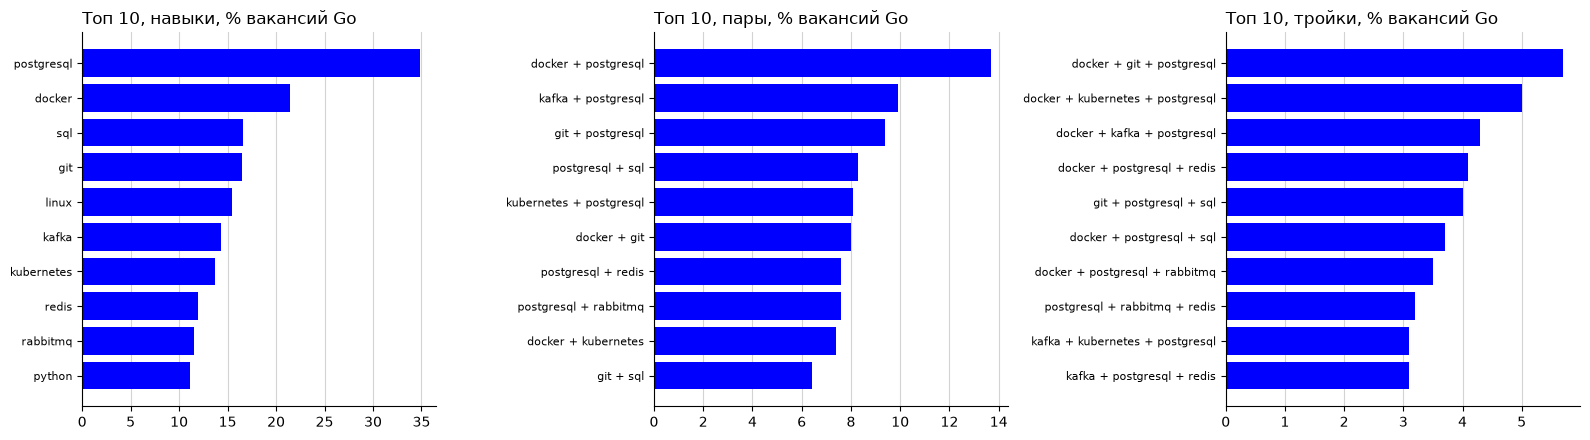

In [36]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for axis, size, title in zip(axes, (1, 2, 3), ("навыки", "пары", "тройки")):
    table = top_tables[size][::-1]
    axis.barh(table["сочетание"], table["доля, %"], color=BLUE)
    axis.set_title("Топ 10, " + title + ", % вакансий Go", loc="left")
    axis.tick_params(axis="y", labelsize=8)
    axis.grid(axis="x", color="lightgray")
    axis.set_axisbelow(True)
    
figure.tight_layout()
figure.savefig(OUT / "top_combos.png", dpi=150)
plt.show()

Вакансия с n уникальными навыками даёт n навыков, C(n,2) = n*(n-1)/2 пар и C(n,3) = n*(n-1)*(n-2)/6 троек, при n = 6 это 15 пар и 20 троек, при n = 20 уже 190 и 1140

In [37]:
histogram = mr_summary["skills_per_vacancy"]
distribution = pd.DataFrame({"навыков n": list(histogram.keys()), "вакансий": list(histogram.values())})
distribution["C(n,2)"] = [math.comb(n, 2) for n in distribution["навыков n"]]
distribution["C(n,3)"] = [math.comb(n, 3) for n in distribution["навыков n"]]
distribution["пар всего"] = distribution["C(n,2)"] * distribution["вакансий"]
distribution["троек всего"] = distribution["C(n,3)"] * distribution["вакансий"]
print(distribution)

    навыков n  вакансий  C(n,2)  C(n,3)  пар всего  троек всего
0           0       665       0       0          0            0
1           1       131       0       0          0            0
2           2       200       1       0        200            0
3           3       244       3       1        732          244
4           4       316       6       4       1896         1264
5           5       303      10      10       3030         3030
6           6       245      15      20       3675         4900
7           7       233      21      35       4893         8155
8           8       144      28      56       4032         8064
9           9       103      36      84       3708         8652
10         10       110      45     120       4950        13200
11         11        50      55     165       2750         8250
12         12        46      66     220       3036        10120
13         13        21      78     286       1638         6006
14         14        16      91     364 

Все три способа дали одинаковые 853 навыка, 10999 пар и 67009 троек, SHA-256 совпали, после падения воркера результат тот же. Пар и троек больше из-за C(n,k): 3.5% вакансий с 15 навыками и больше дают половину всех троек

## 8. Те же решения на Parquet

Все три способа читают Parquet из ETL: первый вариант берёт навыки строкой и считает, как на CSV, второй берёт номера навыков, считает сочетания чисел и переводит их в названия на выходе

In [38]:
%%measure 3 MapReduce Parquet
mr_parquet_summary, _ = mapreduce_job.run("parquet")

[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet попытка 1 время 5.7 с, пик памяти 704 МиБ, прирост 273 МиБ
[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet попытка 2 время 4.1 с, пик памяти 696 МиБ, прирост 257 МиБ
[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet попытка 3 время 4.7 с, пик памяти 710 МиБ, прирост 262 МиБ


In [39]:
%%measure 3 DuckDB Parquet
duck_parquet_summary, _ = duckdb_job.run("parquet")

DuckDB Parquet попытка 1 время 2.7 с, пик памяти 553 МиБ, прирост 109 МиБ
DuckDB Parquet попытка 2 время 1.5 с, пик памяти 577 МиБ, прирост 29 МиБ
DuckDB Parquet попытка 3 время 1.7 с, пик памяти 582 МиБ, прирост 11 МиБ


In [40]:
%%measure 3 Polars Parquet
polars_parquet_summary, _ = polars_job.run("parquet")

polars parquet, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet попытка 1 время 1.1 с, пик памяти 770 МиБ, прирост 198 МиБ


polars parquet, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet попытка 2 время 1.0 с, пик памяти 800 МиБ, прирост 63 МиБ


polars parquet, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet попытка 3 время 1.0 с, пик памяти 819 МиБ, прирост 21 МиБ


In [41]:
%%measure 3 MapReduce Parquet номера
mr_ids_summary, _ = mapreduce_job.run("parquet_ids")

[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet_ids, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet номера попытка 1 время 4.6 с, пик памяти 1005 МиБ, прирост 323 МиБ
[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet_ids, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet номера попытка 2 время 4.3 с, пик памяти 1004 МиБ, прирост 264 МиБ
[master] row group всего 59 с нужной ролью по статистике min/max 1


mapreduce parquet_ids, map тасков:   0%|          | 0/1 [00:00<?, ?it/s]

MapReduce Parquet номера попытка 3 время 4.3 с, пик памяти 1019 МиБ, прирост 284 МиБ


In [42]:
%%measure 3 DuckDB Parquet номера
duck_ids_summary, _ = duckdb_job.run("parquet_ids")

DuckDB Parquet номера попытка 1 время 1.8 с, пик памяти 764 МиБ, прирост 23 МиБ
DuckDB Parquet номера попытка 2 время 1.7 с, пик памяти 763 МиБ, прирост 21 МиБ
DuckDB Parquet номера попытка 3 время 1.8 с, пик памяти 759 МиБ, прирост 17 МиБ


In [43]:
%%measure 3 Polars Parquet номера
polars_ids_summary, _ = polars_job.run("parquet_ids")

polars parquet_ids, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet номера попытка 1 время 1.1 с, пик памяти 839 МиБ, прирост 96 МиБ


polars parquet_ids, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet номера попытка 2 время 1.1 с, пик памяти 844 МиБ, прирост 15 МиБ


polars parquet_ids, строк разработчиков: 0 строк [00:00, ? строк/s]

Polars Parquet номера попытка 3 время 1.0 с, пик памяти 856 МиБ, прирост 23 МиБ


In [44]:
for label, summary in [("MapReduce Parquet", mr_parquet_summary), ("DuckDB Parquet", duck_parquet_summary),
                       ("Polars Parquet", polars_parquet_summary), ("MapReduce Parquet номера", mr_ids_summary),
                       ("DuckDB Parquet номера", duck_ids_summary), ("Polars Parquet номера", polars_ids_summary)]:
    print(label, "вакансий", summary["variant_vacancies"], "результат совпал с CSV:", summary["sha256"] == mr_summary["sha256"])

MapReduce Parquet вакансий 2905 результат совпал с CSV: True
DuckDB Parquet вакансий 2905 результат совпал с CSV: True
Polars Parquet вакансий 2905 результат совпал с CSV: True
MapReduce Parquet номера вакансий 2905 результат совпал с CSV: True
DuckDB Parquet номера вакансий 2905 результат совпал с CSV: True
Polars Parquet номера вакансий 2905 результат совпал с CSV: True


На Parquet все три способа считают за 1.0-4.8 с вместо 2-4 минут на CSV, потому что читают одну row group из 59. Номера навыков вместо строк время не сократили, на 2905 вакансиях сочетаний мало

## 9. Навыки и зарплата

Зарплата есть у части вакансий Go, анализирую рублёвые, валютные смотрю отдельно

Предобработка: границу меньше 10000 считаю опечаткой и умножаю на 1000, если граница одна, вторую восстанавливаю через k (как в разделе 5, только k считаю по вакансиям Go), потом перевожу всё в gross по той же шкале НДФЛ, если флага нет, считаю, что это gross

In [45]:
def fix_bound(value: float | None) -> float:
    if value is None or pd.isna(value):
        return np.nan
        
    if value < 10000:
        return value * 1000
        
    return value


rub = variant[variant["currency"] == "RUR"].copy()
rub["from_rub"] = rub["salary_from"].map(fix_bound)
rub["to_rub"] = rub["salary_to"].map(fix_bound)
both = rub[rub["from_rub"].notna() & rub["to_rub"].notna()]
K = float((both["to_rub"] / both["from_rub"]).median())
hh_ratio = con.execute("""SELECT median(salary_to / salary_from) FROM v
                      WHERE currency = 'RUR' AND salary_from >= 10000 AND salary_to >= 10000""").fetchall()[0][0]
typos = rub[(rub["salary_from"] < 10000) | (rub["salary_to"] < 10000)]
print("опечатки, граница меньше 10000, умножаю на 1000:", len(typos))
print(typos[["name", "area", "salary_from", "salary_to", "from_rub", "to_rub"]].to_string(index=False))
print("k по", len(both), "вакансиям Go с обеими границами:", round(K, 3),
      "квартили", round(float((both["to_rub"] / both["from_rub"]).quantile(0.25)), 2), round(float((both["to_rub"] / both["from_rub"]).quantile(0.75)), 2))
print("для сравнения k по всем вакансиям hh:", round(hh_ratio, 3))

опечатки, граница меньше 10000, умножаю на 1000: 4
                                name            area  salary_from  salary_to  from_rub   to_rub
           Middle Golang-разработчик          Казань        250.0   350000.0  250000.0 350000.0
                   Backend Developer          Москва        200.0   300000.0  200000.0 300000.0
                    Golang Developer Санкт-Петербург        200.0      330.0  200000.0 330000.0
Middle Golang-разработчик (Удаленно)          Казань        250.0   350000.0  250000.0 350000.0
k по 298 вакансиям Go с обеими границами: 1.5 квартили 1.33 1.8
для сравнения k по всем вакансиям hh: 1.316


In [46]:
NDFL = [(5000000, 0.13), (math.inf, 0.15)]


def net_to_gross(net_month: float) -> float:
    annual_net = 12 * net_month
    lower = 0.0
    tax_below = 0.0

    for upper, rate in NDFL:
        net_at_upper = (lower - tax_below) + (upper - lower) * (1 - rate)

        if annual_net <= net_at_upper:
            return (lower + (annual_net - (lower - tax_below)) / (1 - rate)) / 12
        tax_below = tax_below + rate * (upper - lower)
        lower = upper

    return math.nan


def to_gross(points: pd.Series) -> list[float]:
    return [net_to_gross(point) if flag == "false" else point for point, flag in zip(points, rub["gross"])]


ndfl_examples = pd.DataFrame({"net в месяц": [100000, 300000, 362500, 400000, 800000]})
ndfl_examples["gross"] = [round(net_to_gross(net)) for net in ndfl_examples["net в месяц"]]
ndfl_examples

,net в месяц,gross
0,100000,114943
1,300000,344828
2,362500,416667
3,400000,460784
4,800000,931373


In [47]:
rub["from_full"] = rub["from_rub"].fillna(rub["to_rub"] / K)
rub["to_full"] = rub["to_rub"].fillna(rub["from_rub"] * K)
rub["gross_rub"] = to_gross((rub["from_full"] + rub["to_full"]) / 2)
rub["gross_simple"] = to_gross(rub[["from_rub", "to_rub"]].mean(axis=1))
rub = rub[rub["gross_rub"].notna()].reset_index(drop=True)
OVERALL_MEDIAN = rub["gross_rub"].median()
print("рублёвых вакансий с зарплатой", len(rub), "из", len(variant))
print("флаг gross:", rub["gross"].fillna("нет").value_counts().to_dict())
print("опубликованы с", rub["published_at"].min().date(), "по", rub["published_at"].max().date())
print("медиана gross", round(OVERALL_MEDIAN), "P25", round(rub["gross_rub"].quantile(0.25)), "P75", round(rub["gross_rub"].quantile(0.75)))
print("медиана, если не восстанавливать границу через k (середина, а при одной границе она сама)", round(rub["gross_simple"].median()))

рублёвых вакансий с зарплатой 729 из 2905
флаг gross: {'false': 562, 'true': 167}
опубликованы с 2023-12-19 по 2024-09-14
медиана gross 287356 P25 201149 P75 375000
медиана, если не восстанавливать границу через k (середина, а при одной границе она сама) 287356


In [48]:
foreign = variant[variant["currency"].notna() & (variant["currency"] != "RUR")].copy()
foreign["point"] = foreign[["salary_from", "salary_to"]].mean(axis=1)
foreign.groupby("currency").agg(вакансий=("vacancy_id", "count"), медиана_в_валюте=("point", "median"),
                                регионы=("area", lambda areas: ", ".join(area + " " + str(count) for area, count
                                                                          in areas.value_counts().head(3).items())))

,вакансий,медиана_в_валюте,регионы
currency,,,
EUR,2,3025.0,Москва 2
KZT,3,650000.0,Алматы 3
USD,47,4000.0,"Москва 31, Санкт-Петербург 13, Самара 1"


Кроме навыков зарплату двигают опыт, формат работы и регион, и если навык чаще встречается в вакансиях с большим опытом или в Москве, его прибавка может оказаться прибавкой за опыт или за Москву

In [49]:
for column in ["experience", "schedule"]:
    print(rub.groupby(column)["gross_rub"].agg(["count", "median"]).round().sort_values("median"))
    
    print()
    
rub["moscow"] = rub["area"] == "Москва"
print(rub.groupby("moscow")["gross_rub"].agg(["count", "median"]).round())

                    count    median
experience                         
Нет опыта              37   75000.0
От 1 года до 3 лет    260  210728.0
От 3 до 6 лет         389  335249.0
Более 6 лет            43  431373.0

                  count    median
schedule                         
Гибкий график        40  229885.0
Полный день         392  275287.0
Удаленная работа    297  316092.0

        count    median
moscow                 
False     339  250000.0
True      390  326293.0


Прибавку считаю так: go в сочетания не беру, как и в топ-10 выше, пара это два других навыка, тройка три. У одного навыка база это все вакансии Go с зарплатой, прибавка = медиана вакансий с навыком минус общая медиана. У пары A + B базой беру навык, который чаще встречается в вакансиях Go (частоты из результата MapReduce), второй считаю добавленным, прибавка = медиана вакансий с обоими навыками минус медиана вакансий с базовым. У тройки база это самая частая из трёх её пар, добавленный это оставшийся навык. Беру сочетания, которые есть хотя бы в 20 рублёвых вакансиях с зарплатой и у 10 разных работодателей, чтобы не было байеса в сторону 1 работодателя

Рядом у базы и у сочетания доли вакансий с опытом 1-3 года, от 3 лет, удалённых и московских, и прибавка внутри одной группы опыта, отдельно "От 1 года до 3 лет" и "От 3 до 6 лет" (если там хотя бы по 10 вакансий)

In [50]:
MIN_SUPPORT = 20
MIN_EMPLOYERS = 10
skill_frequency = {combo[0]: count for combo, count in mr_rows[1]}
pair_frequency = {combo: count for combo, count in mr_rows[2]}
gross = rub["gross_rub"].to_numpy()
gross_simple = rub["gross_simple"].to_numpy()
senior = rub["experience"].isin(["От 3 до 6 лет", "Более 6 лет"]).to_numpy()
middle = (rub["experience"] == "От 3 до 6 лет").to_numpy()
junior = (rub["experience"] == "От 1 года до 3 лет").to_numpy()
remote = (rub["schedule"] == "Удаленная работа").to_numpy()
moscow = rub["moscow"].to_numpy()
employers = rub["employer_id"].to_numpy()

members = defaultdict(list)

for row, skills in enumerate(rub["skills"]):
    other = [skill for skill in skills if skill != "go"]
    
    for size in (1, 2, 3):
        for combo in combinations(other, size):
            members[combo].append(row)

            
def group_uplift(rows: list[int], base_rows: list[int], group: np.ndarray) -> float:
    inside = [row for row in rows if group[row]]
    base_inside = [row for row in base_rows if group[row]]
    
    if len(inside) < 10 or len(base_inside) < 10:
        return np.nan
        
    return round(np.median(gross[inside]) - np.median(gross[base_inside]))


all_rows = list(range(len(rub)))
uplift_rows = []

for combo, rows in members.items():
    if len(rows) < MIN_SUPPORT:
        continue
        
    if len(combo) == 1:
        base_key: tuple[str, ...] = ("go",)
    elif len(combo) == 2:
        base_key = (min(combo, key=lambda skill: (-skill_frequency[skill], skill)),)
    else:
        base_key = min(combinations(combo, 2), key=lambda pair: (-pair_frequency[pair], pair))
    base_rows = all_rows if len(combo) == 1 else members[base_key]
    uplift_rows.append({
            "k": len(combo),
            "сочетание": " + ".join(combo),
            "база": " + ".join(base_key),
            "добавлен": [skill for skill in combo if skill not in base_key][0],
            "n базы": len(base_rows),
            "n": len(rows),
            "работодателей": len(set(employers[rows])),
            "медиана базы": round(np.median(gross[base_rows])),
            "медиана сочетания": round(np.median(gross[rows])),
            "прибавка": round(np.median(gross[rows]) - np.median(gross[base_rows])),
            "прибавка простым способом": round(np.median(gross_simple[rows]) - np.median(gross_simple[base_rows])),
            "прибавка внутри 1-3 лет": group_uplift(rows, base_rows, junior),
            "прибавка внутри 3-6 лет": group_uplift(rows, base_rows, middle),
            "опыт 1-3 база, %": round(100 * junior[base_rows].mean()),
            "опыт 1-3, %": round(100 * junior[rows].mean()),
            "опыт 3+ база, %": round(100 * senior[base_rows].mean()),
            "опыт 3+, %": round(100 * senior[rows].mean()),
            "удалёнка база, %": round(100 * remote[base_rows].mean()),
            "удалёнка, %": round(100 * remote[rows].mean()),
            "Москва база, %": round(100 * moscow[base_rows].mean()),
            "Москва, %": round(100 * moscow[rows].mean()),
        })
        
uplift = pd.DataFrame(uplift_rows)
uplift["прибавка, %"] = (100 * uplift["прибавка"] / uplift["медиана базы"]).round(1)
excluded = uplift[uplift["работодателей"] < MIN_EMPLOYERS]
uplift = uplift[uplift["работодателей"] >= MIN_EMPLOYERS]
print("отсеяно, потому что меньше", MIN_EMPLOYERS, "работодателей: навыков", int((excluded["k"] == 1).sum()),
      "пар", int((excluded["k"] == 2).sum()), "троек", int((excluded["k"] == 3).sum()))
print("отсеянные навыки:", ", ".join(excluded.loc[excluded["k"] == 1, "сочетание"]))
print()
print("самые большие прибавки среди отсеянных:")
print(excluded.sort_values("прибавка", ascending=False)[["сочетание", "n", "работодателей", "медиана сочетания", "прибавка"]]
      .head(8).to_string(index=False))
print()
singles = uplift[uplift["k"] == 1].drop(columns="k").reset_index(drop=True)
pairs = uplift[uplift["k"] == 2].drop(columns="k").reset_index(drop=True)
triples = uplift[uplift["k"] == 3].drop(columns="k").reset_index(drop=True)
print("в анализе: навыков", len(singles), "пар", len(pairs), "троек", len(triples))
SHOWN = ["сочетание", "база", "n", "работодателей", "медиана базы", "медиана сочетания", "прибавка", "прибавка внутри 1-3 лет",
         "прибавка внутри 3-6 лет", "опыт 1-3 база, %", "опыт 1-3, %", "опыт 3+ база, %", "опыт 3+, %", "удалёнка база, %",
         "удалёнка, %", "Москва база, %", "Москва, %"]

отсеяно, потому что меньше 10 работодателей: навыков 5 пар 31 троек 98
отсеянные навыки: devops, atlassian jira, веб-программирование, github, gitlab

самые большие прибавки среди отсеянных:
                сочетание  n  работодателей  медиана сочетания  прибавка
             gitlab + ооп 24              1             383311    153426
             github + ооп 24              1             383311    153426
   mysql + php + rabbitmq 20              5             375000    145115
      mysql + php + redis 20              9             367098    137213
gitlab + postgresql + ооп 24              1             383311    124690
             gitlab + sql 24              1             383311    124690
       git + github + ооп 24              1             383311    124690
       git + gitlab + sql 24              1             383311    124690

в анализе: навыков 27 пар 84 троек 41


Навыки по одному, которые сильнее всего повышают медиану, база это все вакансии Go

In [51]:
singles.sort_values("прибавка", ascending=False)[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
13,ci/cd,go,28,17,287356,375000,87644,NaN,39751.0,36,18,59,79,41,39,53,64
15,kubernetes,go,85,45,287356,335249,47893,63697.0,9579.0,36,21,59,76,41,52,53,66
22,api,go,65,26,287356,335249,47893,-72797.0,0.0,36,20,59,77,41,78,53,38
18,unit testing,go,23,10,287356,316092,28736,NaN,9579.0,36,30,59,70,41,70,53,87
19,clickhouse,go,61,33,287356,316092,28736,13410.0,0.0,36,25,59,75,41,61,53,54
11,rabbitmq,go,127,45,287356,316092,28736,1916.0,0.0,36,29,59,69,41,35,53,52
16,базы данных,go,57,17,287356,304598,17241,-32567.0,9579.0,36,25,59,75,41,65,53,42
12,redis,go,131,65,287356,287356,0,13410.0,9579.0,36,34,59,63,41,46,53,53
9,docker,go,221,108,287356,287356,0,-8860.0,9579.0,36,29,59,70,41,51,53,56
10,linux,go,121,72,287356,287356,0,-9579.0,-47893.0,36,42,59,56,41,34,53,63


Навыки по одному, которые сильнее всего понижают медиану

In [52]:
singles.sort_values("прибавка")[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
25,node.js,go,20,13,287356,166667,-120690,NaN,NaN,36,30,59,45,41,40,53,45
26,html,go,20,10,287356,179598,-107759,NaN,-53999.0,36,40,59,60,41,15,53,25
5,python,go,100,56,287356,222701,-64655,-67050.0,-56837.0,36,42,59,51,41,26,53,41
8,c++,go,22,14,287356,228065,-59291,NaN,-33525.0,36,41,59,50,41,5,53,41
7,ооп,go,85,21,287356,229885,-57471,0.0,-76628.0,36,33,59,64,41,41,53,26
2,mysql,go,123,60,287356,229885,-57471,-67050.0,-56513.0,36,36,59,59,41,40,53,42
3,php,go,89,42,287356,229885,-57471,-49808.0,-83812.0,36,33,59,64,41,37,53,29
1,javascript,go,60,27,287356,229885,-57471,-85728.0,-105364.0,36,35,59,60,41,22,53,27
20,rest,go,65,34,287356,250000,-37356,-57471.0,-22749.0,36,45,59,49,41,29,53,69
6,sql,go,157,77,287356,258621,-28736,-49808.0,-19157.0,36,43,59,54,41,46,53,39


Пары, которые силнее всего повышают медиану

In [53]:
pairs.sort_values("прибавка", ascending=False)[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
52,rabbitmq + sql,sql,36,14,258621,347222,88602,25862.0,31130.0,43,39,54,61,46,28,39,33
35,ci/cd + docker,docker,23,12,287356,375000,87644,NaN,30172.0,29,22,70,74,51,35,56,61
69,clickhouse + git,git,25,13,258621,344828,86207,NaN,9579.0,40,8,53,92,40,60,46,72
64,api + git,git,42,16,258621,335249,76628,NaN,0.0,40,14,53,81,40,74,46,33
83,git + базы данных,git,43,10,258621,335249,76628,NaN,9579.0,40,21,53,79,40,84,46,44
65,api + sql,sql,47,14,258621,335249,76628,NaN,19157.0,43,19,54,77,46,85,39,30
49,docker + php,docker,32,16,287356,359195,71839,NaN,-4310.0,29,25,70,75,51,41,56,41
63,api + docker,docker,42,11,287356,347222,59866,NaN,-9579.0,29,7,70,93,51,81,56,33
21,docker + rabbitmq,docker,55,26,287356,344828,57471,22270.0,0.0,29,20,70,78,51,44,56,56
34,rabbitmq + redis,redis,58,22,287356,344828,57471,0.0,14368.0,34,24,63,76,46,33,53,53


Пары, которые сильнее всего понижают медиану

In [54]:
pairs.sort_values("прибавка")[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
0,git + javascript,git,20,13,258621,109195,-149425,-34483.0,NaN,40,55,53,30,40,25,46,25
74,rest + sql,sql,21,15,258621,137931,-120690,-28736.0,NaN,43,52,54,33,46,43,39,62
1,git + mysql,git,52,31,258621,169540,-89080,-21178.0,-47893.0,40,54,53,35,40,44,46,52
67,backend + git,git,20,15,258621,179598,-79023,-15086.0,NaN,40,60,53,35,40,45,46,55
2,git + php,git,32,20,258621,183908,-74713,-26580.0,NaN,40,62,53,28,40,31,46,31
16,python + sql,sql,39,23,258621,186782,-71839,-48851.0,-65532.0,43,56,54,36,46,23,39,31
26,linux + mysql,linux,25,18,287356,215517,-71839,-43103.0,-8621.0,42,40,56,52,34,36,63,64
14,postgresql + python,postgresql,40,20,287356,224138,-63218,-79023.0,-64464.0,37,45,58,45,46,25,53,30
43,kubernetes + redis,kubernetes,31,19,335249,287356,-47893,NaN,-7184.0,21,16,76,81,52,48,66,58
10,mysql + postgresql,postgresql,46,25,287356,240482,-46875,-82701.0,-75610.0,37,41,58,50,46,39,53,35


Тройки, которые сильнее всего повышают медиану

In [55]:
triples.sort_values("прибавка", ascending=False)[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
30,docker + mysql + php,docker + mysql,24,11,287356,375000,87644,NaN,15805.0,36,25,62,75,38,38,51,33
20,docker + grpc + postgresql,docker + postgresql,24,13,316092,395284,79192,NaN,115957.0,26,21,72,75,57,50,51,46
35,api + git + sql,git + sql,35,10,258621,335249,76628,NaN,59866.0,41,14,56,80,46,83,36,29
24,grpc + postgresql + redis,postgresql + redis,23,11,287356,359195,71839,NaN,NaN,38,39,57,57,43,48,51,43
37,api + git + postgresql,git + postgresql,36,11,272989,335249,62261,NaN,-9579.0,36,14,56,81,44,78,44,25
19,postgresql + rabbitmq + redis,postgresql + redis,41,16,287356,344828,57471,-89080.0,-14368.0,38,24,57,76,43,41,51,63
15,docker + rabbitmq + redis,docker + redis,38,16,287356,344828,57471,0.0,0.0,38,26,61,74,45,34,52,55
36,clickhouse + docker + redis,docker + redis,21,10,287356,344828,57471,NaN,14368.0,38,38,61,62,45,48,52,43
34,kafka + postgresql + rabbitmq,kafka + postgresql,33,13,289511,344828,55316,-101533.0,-4789.0,35,30,64,70,39,27,69,67
22,docker + kubernetes + rabbitmq,docker + kubernetes,22,12,316092,366379,50287,NaN,47893.0,15,18,83,82,53,41,60,55


Тройки, которые сильнее всего понижают медиану

In [56]:
triples.sort_values("прибавка")[SHOWN].head(10)

,сочетание,база,n,работодателей,медиана базы,медиана сочетания,прибавка,прибавка внутри 1-3 лет,прибавка внутри 3-6 лет,"опыт 1-3 база, %","опыт 1-3, %","опыт 3+ база, %","опыт 3+, %","удалёнка база, %","удалёнка, %","Москва база, %","Москва, %"
1,git + mysql + postgresql,git + postgresql,25,14,272989,140000,-132989,-61782.0,NaN,36,60,56,24,44,32,44,28
0,git + mysql + php,mysql + php,21,12,229885,125000,-104885,-25144.0,NaN,32,67,66,29,37,29,27,33
31,docker + git + rest,docker + git,23,15,287356,242500,-44856,NaN,-86207.0,31,30,68,70,46,26,57,78
6,docker + git + mysql,docker + git,20,13,287356,250060,-37296,-17122.0,NaN,31,55,68,40,46,35,57,70
2,git + postgresql + python,git + postgresql,29,13,272989,239464,-33525,-77586.0,-69253.0,36,45,56,45,44,10,44,28
33,git + postgresql + rest,git + postgresql,21,14,272989,242500,-30489,NaN,-86207.0,36,29,56,57,44,24,44,57
21,docker + kubernetes + postgresql,docker + postgresql,30,19,316092,287356,-28736,NaN,-16164.0,26,27,72,70,57,63,51,63
10,docker + linux + postgresql,docker + postgresql,29,18,316092,287356,-28736,NaN,-57471.0,26,21,72,79,57,17,51,48
11,docker + mysql + postgresql,docker + postgresql,21,12,316092,287356,-28736,NaN,NaN,26,29,72,67,57,52,51,43
4,git + python + sql,git + sql,27,14,258621,239464,-19157,-40230.0,-44856.0,41,52,56,48,46,15,36,33


Проверка способа: если считать зарплату проще (середина или то, что есть), совпадают ли топ-10 пар вверх и вниз

In [57]:
for ascending, title in [(False, "повышают"), (True, "понижают")]:
    main_top = set(pairs.sort_values("прибавка", ascending=ascending).head(10)["сочетание"])
    simple_top = set(pairs.sort_values("прибавка простым способом", ascending=ascending).head(10)["сочетание"])
    
    print(title, ": общих пар в топ 10", len(main_top & simple_top), "из 10")
    
print("корреляция прибавок двух способов по всем парам", round(pairs["прибавка"].corr(pairs["прибавка простым способом"]), 3))

повышают : общих пар в топ 10 5 из 10
понижают : общих пар в топ 10 8 из 10
корреляция прибавок двух способов по всем парам 0.851


Итоговая таблица по навыкам

In [58]:
skill_rows = []

for skill, group in pairs.groupby("добавлен"):
    if len(group) < 2:
        continue
    rows = members[(skill,)]
    skill_rows.append({"навык": skill, "пар где добавлен": len(group),
                       "медиана прибавки в парах": round(group["прибавка"].median()),
                       "медиана с навыком": round(np.median(gross[rows])), "n": len(rows),
                       "к общей медиане": round(np.median(gross[rows]) - OVERALL_MEDIAN),
                       "опыт 1-3, %": round(100 * junior[rows].mean()),
                       "опыт 3+, %": round(100 * senior[rows].mean()),
                       "Москва, %": round(100 * moscow[rows].mean())})
                       
skill_effect = pd.DataFrame(skill_rows).sort_values("медиана прибавки в парах", ascending=False).reset_index(drop=True)
print("общая медиана gross", round(OVERALL_MEDIAN), "по", len(rub), "вакансиям, опыт 1-3 у", round(100 * junior.mean()), "%, опыт 3+ у",
      round(100 * senior.mean()), "%")
print("повышают:")
print(skill_effect.head(10))
print()
print("понижают:")
print(skill_effect.tail(10).iloc[::-1])

общая медиана gross 287356 по 729 вакансиям, опыт 1-3 у 36 %, опыт 3+ у 59 %
повышают:
         навык  пар где добавлен  медиана прибавки в парах  медиана с навыком    n  к общей медиане  опыт 1-3, %  опыт 3+, %  Москва, %
0          api                 4                     68247             335249   65            47893           20          77         38
1   clickhouse                 4                     52682             316092   61            28736           25          75         54
2  базы данных                 3                     47893             304598   57            17241           25          75         42
3     rabbitmq                 7                     31130             316092  127            28736           29          69         52
4   kubernetes                 3                     28736             335249   85            47893           21          76         66
5     rest api                 3                     28736             278678   44            -86

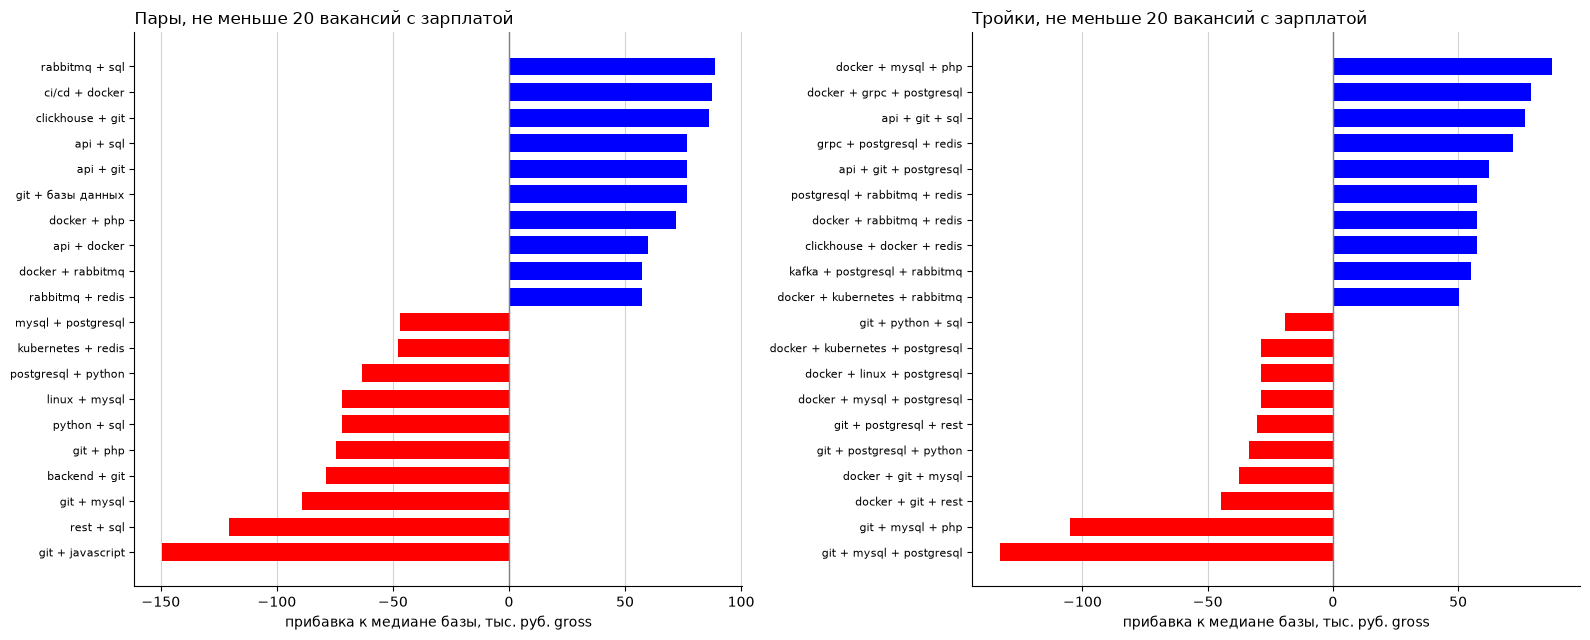

In [59]:
figure, axes = plt.subplots(1, 2, figsize=(16, 6.5))

for axis, table, title in [(axes[0], pairs, "Пары"), (axes[1], triples, "Тройки")]:
    shown = pd.concat([table.nlargest(10, "прибавка"), table.nsmallest(10, "прибавка")]).sort_values("прибавка")
    colors = ["blue" if value > 0 else "red" for value in shown["прибавка"]]
    axis.barh(shown["сочетание"], shown["прибавка"] / 1000, color=colors, height=0.7)
    axis.axvline(0, color="gray", linewidth=1)
    axis.set_xlabel("прибавка к медиане базы, тыс. руб. gross")
    axis.set_title(title + ", не меньше 20 вакансий с зарплатой", loc="left")
    axis.tick_params(axis="y", labelsize=8)
    axis.grid(axis="x", color="lightgray")
    axis.set_axisbelow(True)
    
figure.tight_layout()
figure.savefig(OUT / "uplift.png", dpi=150)
plt.show()

Повышают зарплату ci/cd и kubernetes, прибавка у них держится и при одинаковом опыте, у api и clickhouse + git её даёт опыт. Понижают python, mysql, php и javascript внутри обеих групп опыта, это вакансии, где Go второй язык рядом с PHP, Python или JS, и работодатели платят за такие смешанные позиции меньше

## 10. Регионы

In [60]:
REGIONS = ["Москва", "Санкт-Петербург", "Екатеринбург"]
variant["other_skills"] = variant["skills"].map(lambda skills: [skill for skill in skills if skill != "go"])


def region_profile(frame: pd.DataFrame, salary_frame: pd.DataFrame) -> dict[str, float]:
    with_skills = frame[frame["other_skills"].map(len) > 0]
    employers = frame["employer_id"].value_counts()
    junior_salary = salary_frame["experience"] == "От 1 года до 3 лет"
    senior_salary = salary_frame["experience"].isin(["От 3 до 6 лет", "Более 6 лет"])
    
    return {
        "вакансий": len(frame),
        "доля от всех Go вакансий, %": round(100 * len(frame) / len(variant), 1),
        "с навыками кроме go, %": round(100 * len(with_skills) / len(frame), 1),
        "навыков на вакансию кроме go": round(with_skills["other_skills"].map(len).mean(), 1),
        "с зарплатой в рублях": len(salary_frame),
        "медиана gross": round(salary_frame["gross_rub"].median()),
        "P25 gross": round(salary_frame["gross_rub"].quantile(0.25)),
        "P75 gross": round(salary_frame["gross_rub"].quantile(0.75)),
        "с зарплатой, опыт 1-3 года": int(junior_salary.sum()),
        "медиана gross, опыт 1-3 года": round(salary_frame.loc[junior_salary, "gross_rub"].median()),
        "с зарплатой, опыт от 3 лет": int(senior_salary.sum()),
        "медиана gross, опыт от 3 лет": round(salary_frame.loc[senior_salary, "gross_rub"].median()),
        "удалённая работа, %": round(100 * (frame["schedule"] == "Удаленная работа").mean(), 1),
        "опыт 1-3 года, %": round(100 * (frame["experience"] == "От 1 года до 3 лет").mean(), 1),
        "опыт от 3 лет, %": round(100 * frame["experience"].isin(["От 3 до 6 лет", "Более 6 лет"]).mean(), 1),
        "без опыта, %": round(100 * (frame["experience"] == "Нет опыта").mean(), 1),
        "работодателей": frame["employer_id"].nunique(),
        "доля топ 5 работодателей, %": round(100 * employers.head(5).sum() / len(frame), 1),
    }


profiles = {}

for region in REGIONS:
    profiles[region] = region_profile(variant[variant["area"] == region], rub[rub["area"] == region])
    
profiles["вся выборка"] = region_profile(variant, rub)

pd.DataFrame(profiles)

,Москва,Санкт-Петербург,Екатеринбург,вся выборка
вакансий,1750.0,411.0,93.0,2905.0
"доля от всех Go вакансий, %",60.2,14.1,3.2,100.0
"с навыками кроме go, %",70.7,77.6,69.9,73.0
навыков на вакансию кроме go,5.1,5.1,4.8,5.3
с зарплатой в рублях,390.0,100.0,24.0,729.0
медиана gross,326293.0,304598.0,227011.0,287356.0
P25 gross,247126.0,258621.0,156609.0,201149.0
P75 gross,431373.0,400000.0,288017.0,375000.0
"с зарплатой, опыт 1-3 года",119.0,27.0,12.0,260.0
"медиана gross, опыт 1-3 года",239464.0,287356.0,224138.0,210728.0


In [61]:
def top_combos(frame: pd.DataFrame, size: int, count: int) -> list[str]:
    counter: Counter[tuple[str, ...]] = Counter()
    
    for skills in frame["other_skills"]:
        counter.update(combinations(skills, size))
        
    base = int((frame["other_skills"].map(len) > 0).sum())
    
    return [" + ".join(combo) + " (" + str(value) + ", " + str(round(100 * value / base)) + "%)"
            for combo, value in counter.most_common(count)]


blocks = []

for size, count, title in [(1, 10, "навык"), (2, 5, "пара"), (3, 5, "тройка")]:
    block = pd.DataFrame({region: top_combos(variant[variant["area"] == region], size, count) for region in REGIONS})
    block.index = [title + " " + str(position) for position in range(1, count + 1)]
    blocks.append(block)
    
pd.concat(blocks)

,Москва,Санкт-Петербург,Екатеринбург
навык 1,"postgresql (596, 48%)","postgresql (154, 48%)","postgresql (20, 31%)"
навык 2,"docker (383, 31%)","docker (94, 29%)","python (18, 28%)"
навык 3,"kafka (268, 22%)","sql (71, 22%)","git (16, 25%)"
навык 4,"kubernetes (267, 22%)","kubernetes (63, 20%)","linux (15, 23%)"
навык 5,"git (256, 21%)","linux (63, 20%)","rabbitmq (14, 22%)"
навык 6,"linux (255, 21%)","kafka (56, 18%)","php (13, 20%)"
навык 7,"sql (255, 21%)","redis (53, 17%)","docker (12, 18%)"
навык 8,"redis (210, 17%)","git (47, 15%)","sql (11, 17%)"
навык 9,"rabbitmq (181, 15%)","clickhouse (44, 14%)","c++ (9, 14%)"
навык 10,"python (171, 14%)","python (44, 14%)","java (9, 14%)"


Навыки, которые регионы просят по-разному: доля вакансий с навыком среди вакансий региона с навыками кроме go и разница в процентных пунктах, беру навыки, которые есть хотя бы в 15 вакансиях этих трёх регионов

In [62]:
regional = variant[variant["area"].isin(REGIONS) & (variant["other_skills"].map(len) > 0)]
exploded = regional[["vacancy_id", "area", "other_skills"]].explode("other_skills").rename(columns={"other_skills": "skills"})
counts = exploded.groupby(["skills", "area"])["vacancy_id"].count().unstack(fill_value=0)[REGIONS]
share = (100 * counts / regional.groupby("area").size()[REGIONS]).round(1)
share = share[counts.sum(axis=1) >= 15]
share["СПб минус Москва"] = share["Санкт-Петербург"] - share["Москва"]
share["Екб минус Москва"] = share["Екатеринбург"] - share["Москва"]
contrast = pd.concat([share.nlargest(6, "СПб минус Москва"), share.nsmallest(6, "СПб минус Москва"),
                      share.nlargest(6, "Екб минус Москва"), share.nsmallest(6, "Екб минус Москва")])
contrast[~contrast.index.duplicated()]

area,Москва,Санкт-Петербург,Екатеринбург,СПб минус Москва,Екб минус Москва
skills,,,,,
backend,5.5,10.0,3.1,4.5,-2.4
c/c++,1.9,6.0,7.7,4.1,5.8
clickhouse,10.1,13.8,6.2,3.7,-3.9
финансы,1.0,4.7,0.0,3.7,-1.0
ооп,3.3,6.9,6.2,3.6,2.9
разработка логистики,1.6,5.0,1.5,3.4,-0.1
git,20.7,14.7,24.6,-6.0,3.9
kafka,21.6,17.6,4.6,-4.0,-17.0
торговая площадка,2.7,0.0,0.0,-2.7,-2.7


Москва и Петербург похожи по стеку и опыту, а в Екатеринбурге 48% вакансий с опытом 1-3 года, kubernetes нет, python и php рядом с Go встречаются чаще. При одинаковом опыте разрыв с Москвой небольшой, 224138 против 239464 у опыта 1-3 года (в Екатеринбурге 12 зарплат), большую часть разницы в медиане даёт доля младших вакансий

## 11. Профилирование

In [63]:
runs = pd.DataFrame(measurements)
print("всего записей", len(runs))
runs = runs.groupby("способ", sort=False).tail(3).reset_index(drop=True)
runs.to_csv(OUT / "measurements.csv", index=False)
runs

всего записей 28


,способ,попытка,"время, с","пик памяти, МиБ","прирост памяти, МиБ"
0,ETL CSV в Parquet,1,347.9,5179,4993
1,MapReduce CSV,1,150.9,1882,1382
2,MapReduce CSV,2,148.4,1753,1377
3,MapReduce CSV,3,152.3,1679,1468
4,DuckDB CSV,1,230.7,2968,2754
5,DuckDB CSV,2,265.9,2954,2694
6,DuckDB CSV,3,274.0,3021,2733
7,Polars CSV,1,141.5,2086,1809
8,Polars CSV,2,127.4,2032,1437
9,Polars CSV,3,128.6,2060,1551


In [64]:
grouped = runs.groupby("способ", sort=False)

profile = pd.DataFrame({
    "запусков": grouped.size(),
    "время среднее, с": grouped["время, с"].mean().round(1),
    "время std, с": grouped["время, с"].std().round(1),
    "время min, с": grouped["время, с"].min(),
    "пик памяти среднее, МиБ": grouped["пик памяти, МиБ"].mean().round(),
    "прирост памяти среднее, МиБ": grouped["прирост памяти, МиБ"].mean().round(),
    "прирост памяти max, МиБ": grouped["прирост памяти, МиБ"].max(),
})
profile.to_csv(OUT / "profile.csv")
profile

,запусков,"время среднее, с","время std, с","время min, с","пик памяти среднее, МиБ","прирост памяти среднее, МиБ","прирост памяти max, МиБ"
способ,,,,,,,
ETL CSV в Parquet,1,347.9,NaN,347.9,5179.0,4993.0,4993
MapReduce CSV,3,150.5,2.0,148.4,1771.0,1409.0,1468
DuckDB CSV,3,256.9,23.0,230.7,2981.0,2727.0,2754
Polars CSV,3,132.5,7.8,127.4,2059.0,1599.0,1809
MapReduce Parquet,3,4.8,0.8,4.1,703.0,264.0,273
DuckDB Parquet,3,2.0,0.6,1.5,571.0,50.0,109
Polars Parquet,3,1.0,0.1,1.0,796.0,94.0,198
MapReduce Parquet номера,3,4.4,0.2,4.3,1009.0,290.0,323
DuckDB Parquet номера,3,1.8,0.1,1.7,762.0,20.0,23


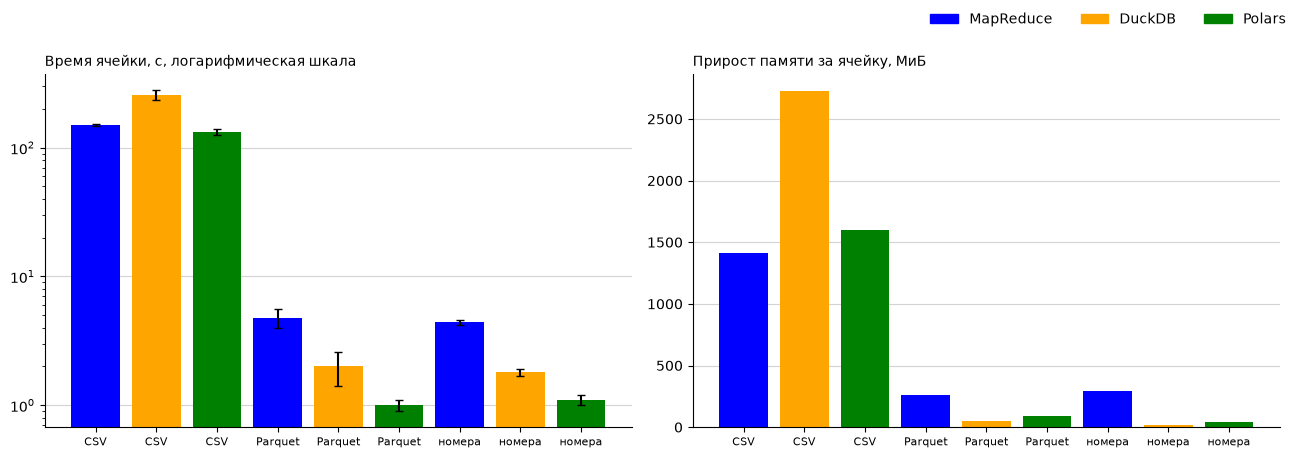

In [65]:
order = ["MapReduce CSV", "DuckDB CSV", "Polars CSV", "MapReduce Parquet", "DuckDB Parquet", "Polars Parquet",
             "MapReduce Parquet номера", "DuckDB Parquet номера", "Polars Parquet номера"]
colors = ["blue", "orange", "green"] * 3
labels = ["CSV"] * 3 + ["Parquet"] * 3 + ["номера"] * 3
figure, (time_axis, memory_axis) = plt.subplots(1, 2, figsize=(13, 4.6))
time_axis.bar(range(9), profile.loc[order, "время среднее, с"], yerr=profile.loc[order, "время std, с"], color=colors, capsize=3)
time_axis.set_yscale("log")

time_axis.set_title("Время ячейки, с, логарифмическая шкала", loc="left", fontsize=10)
memory_axis.bar(range(9), profile.loc[order, "прирост памяти среднее, МиБ"], color=colors)
memory_axis.set_title("Прирост памяти за ячейку, МиБ", loc="left", fontsize=10)

for axis in (time_axis, memory_axis):
    axis.set_xticks(range(9), labels, fontsize=8)
    axis.grid(axis="y", color="lightgray")
    axis.set_axisbelow(True)
    
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors[:3]]
figure.legend(handles, ["MapReduce", "DuckDB", "Polars"], loc="upper right", ncol=3, frameon=False)
figure.tight_layout(rect=(0, 0, 1, 0.92))
figure.savefig(OUT / "profile.png", dpi=150)
plt.show()

Прирост памяти у Polars скачет от попытки к попытке, потому что его аллокатор оставляет освобождённую память себе и переиспользует её в следующем запуске, поэтому сравниваем по среднему приросту, а у MapReduce map работает в новых процессах, и прирост ровный

На CSV быстрее всех Polars (133 с), потом MapReduce (151 с) и DuckDB (257 с): Polars фильтрует роль при чтении, MapReduce не разбирает csv у строк без нужной роли, а DuckDB разбирает все 10 млн строк, отсюда у него и больше памяти. Узкое место у всех чтение 23 ГиБ из RustFS, поэтому на Parquet, где способы читают одну row group, они быстрее в 31-133 раза

In [66]:
print(run_command(sys.executable, "-m", "nbconvert", "--to", "html", "mapreduce.ipynb"))
PRINT_STYLE = """<style>
@page { size: A4 landscape; margin: 8mm; }
@media print {
  .jp-InputPrompt, .jp-OutputPrompt { display: none !important; }
  .jp-OutputArea-output, .jp-OutputArea-child, .jp-Cell-outputWrapper, .jp-Cell-inputWrapper, .jp-InputArea-editor { overflow: visible !important; }
  .jp-RenderedHTMLCommon table { font-size: 8px !important; table-layout: auto !important; }
  .jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { padding: 1px 3px !important; }
  .jp-RenderedText pre, .jp-InputArea-editor pre, .highlight pre { font-size: 8px !important; line-height: 1.25 !important; white-space: pre-wrap !important; word-break: break-all !important; }
  .jp-RenderedImage img { max-width: 100% !important; }
}
</style>
"""
report = PROJECT / "mapreduce.html"
report.write_text(report.read_text(encoding="utf-8").replace("</head>", PRINT_STYLE + "</head>", 1), encoding="utf-8")

[NbConvertApp] Converting notebook mapreduce.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 1087136 bytes to mapreduce.html


1087859